# Supporting Figure S5

![Full Figure](../figures/suppS5_FULL.png)

## Code for Supporting Figure S5: univariate predictors of trained violation rate

**Goal:** Relate each animal's trained violation rate to its trained hit rate and to its training history.

| Section | Predictor | Unit | Statistic |
|---|---|---|---|
| Hit rate — sessions | Trained session hit rate | Session | MixedLM, random intercept per animal |
| Hit rate — animals | Mean trained session hit rate | Animal | OLS / Pearson |
| Fixation-stage violation rate | Mean stage 1 (Grow Nose Poke) session violation rate | Animal | OLS / Pearson |
| Time in fixation stage | Number of stage 1 sessions | Animal | OLS / Pearson |
| Time to trained | Session of the last 72.5% rolling hit-rate crossing | Animal | OLS / Pearson |
| Delay length | Trial delay (2, 3, 4, or 6 s) | Animal × delay | Per-animal slope t-test; paired t-tests vs. 2 s |
| Relative delay | Current delay longer vs. same or shorter than the previous trial's | Animal × condition | Paired t-test; delay-matched difference |
| Session progress | Fraction of the session completed (10 bins; first and last 10 trials excluded) | Animal × bin | Per-animal slope t-test |
| Session edges | First and last 20 trials of each session | Animal × trial | Descriptive |

In the first five sections the outcome is the trained violation rate. N = 16 animals, and each animal keeps the same color in those sections. Rates are percentages; animal values are means of session rates. Predictors other than session hit rate take one value per animal, so they are tested across animals rather than with a session-level mixed model.

The delay and session-position sections compare violation rates across trial conditions within the trained dataset. Rates are pooled over trials within each animal and condition, and tests are across animals.

**Outputs:** none yet; panels are not saved while the figure is in draft.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from violations_glm.config import TRAINED_DELAYS, VIOLATION_COLOR
from violations_glm.io import (
    load_autocorrelation_summary,
    load_history_robustness,
    load_delay_statistics,
    load_delay_violation_rates,
    load_hit_violation_animals,
    load_hit_violation_sessions,
    load_hit_violation_statistics,
    load_relative_delay_violation_rates,
    load_session_edge_rates,
    load_session_position_statistics,
    load_session_progress_violation_rates,
    load_training_predictor_statistics,
    load_training_predictors,
)
from violations_glm.plotting import (
    animal_association_scatter,
    animal_palette,
    configure_publication_dpi,
)
from violations_glm.transforms import RELATIVE_DELAY_ORDER

configure_publication_dpi()

sns.set_context(
    "notebook",
    rc={
        "font.size": 20,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "axes.titleweight": "bold",
        "xtick.labelsize": 15,
        "ytick.labelsize": 15,
    },
)

In [2]:
hit_violation_sessions = load_hit_violation_sessions()
hit_violation_animals = load_hit_violation_animals()
hit_violation_statistics = load_hit_violation_statistics()
training_predictors = load_training_predictors()
training_statistics = load_training_predictor_statistics()
delay_rates = load_delay_violation_rates()
relative_rates = load_relative_delay_violation_rates()
matched_rates = load_relative_delay_violation_rates(matched=True)
delay_statistics = load_delay_statistics()
progress_rates = load_session_progress_violation_rates()
progress_rates_all = load_session_progress_violation_rates(include_edges=True)
edge_rates = load_session_edge_rates()
position_statistics = load_session_position_statistics()

palette = animal_palette()
animal_grays = ["gray"] * delay_rates["animal_id"].nunique()
trained_viol_label = "Trained Violation Rate (%)"

## Trained hit rate vs. violation rate — sessions

Faint points are trained sessions; solid points are animal means. The MixedLM (`viol_rate ~ hit_rate`, random intercept per animal) is the submitted analysis reported in the Results.

          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: viol_rate  
No. Observations: 5210    Method:             REML       
No. Groups:       16      Scale:              42.7760    
Min. group size:  114     Log-Likelihood:     -17220.6603
Max. group size:  552     Converged:          Yes        
Mean group size:  325.6                                  
---------------------------------------------------------
              Coef.  Std.Err.    z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept     45.222    2.117  21.361 0.000 41.072 49.371
hit_rate      -0.342    0.020 -17.265 0.000 -0.380 -0.303
Group Var     30.495    1.712                            

Conditional R² = 0.493; marginal R² = 0.095


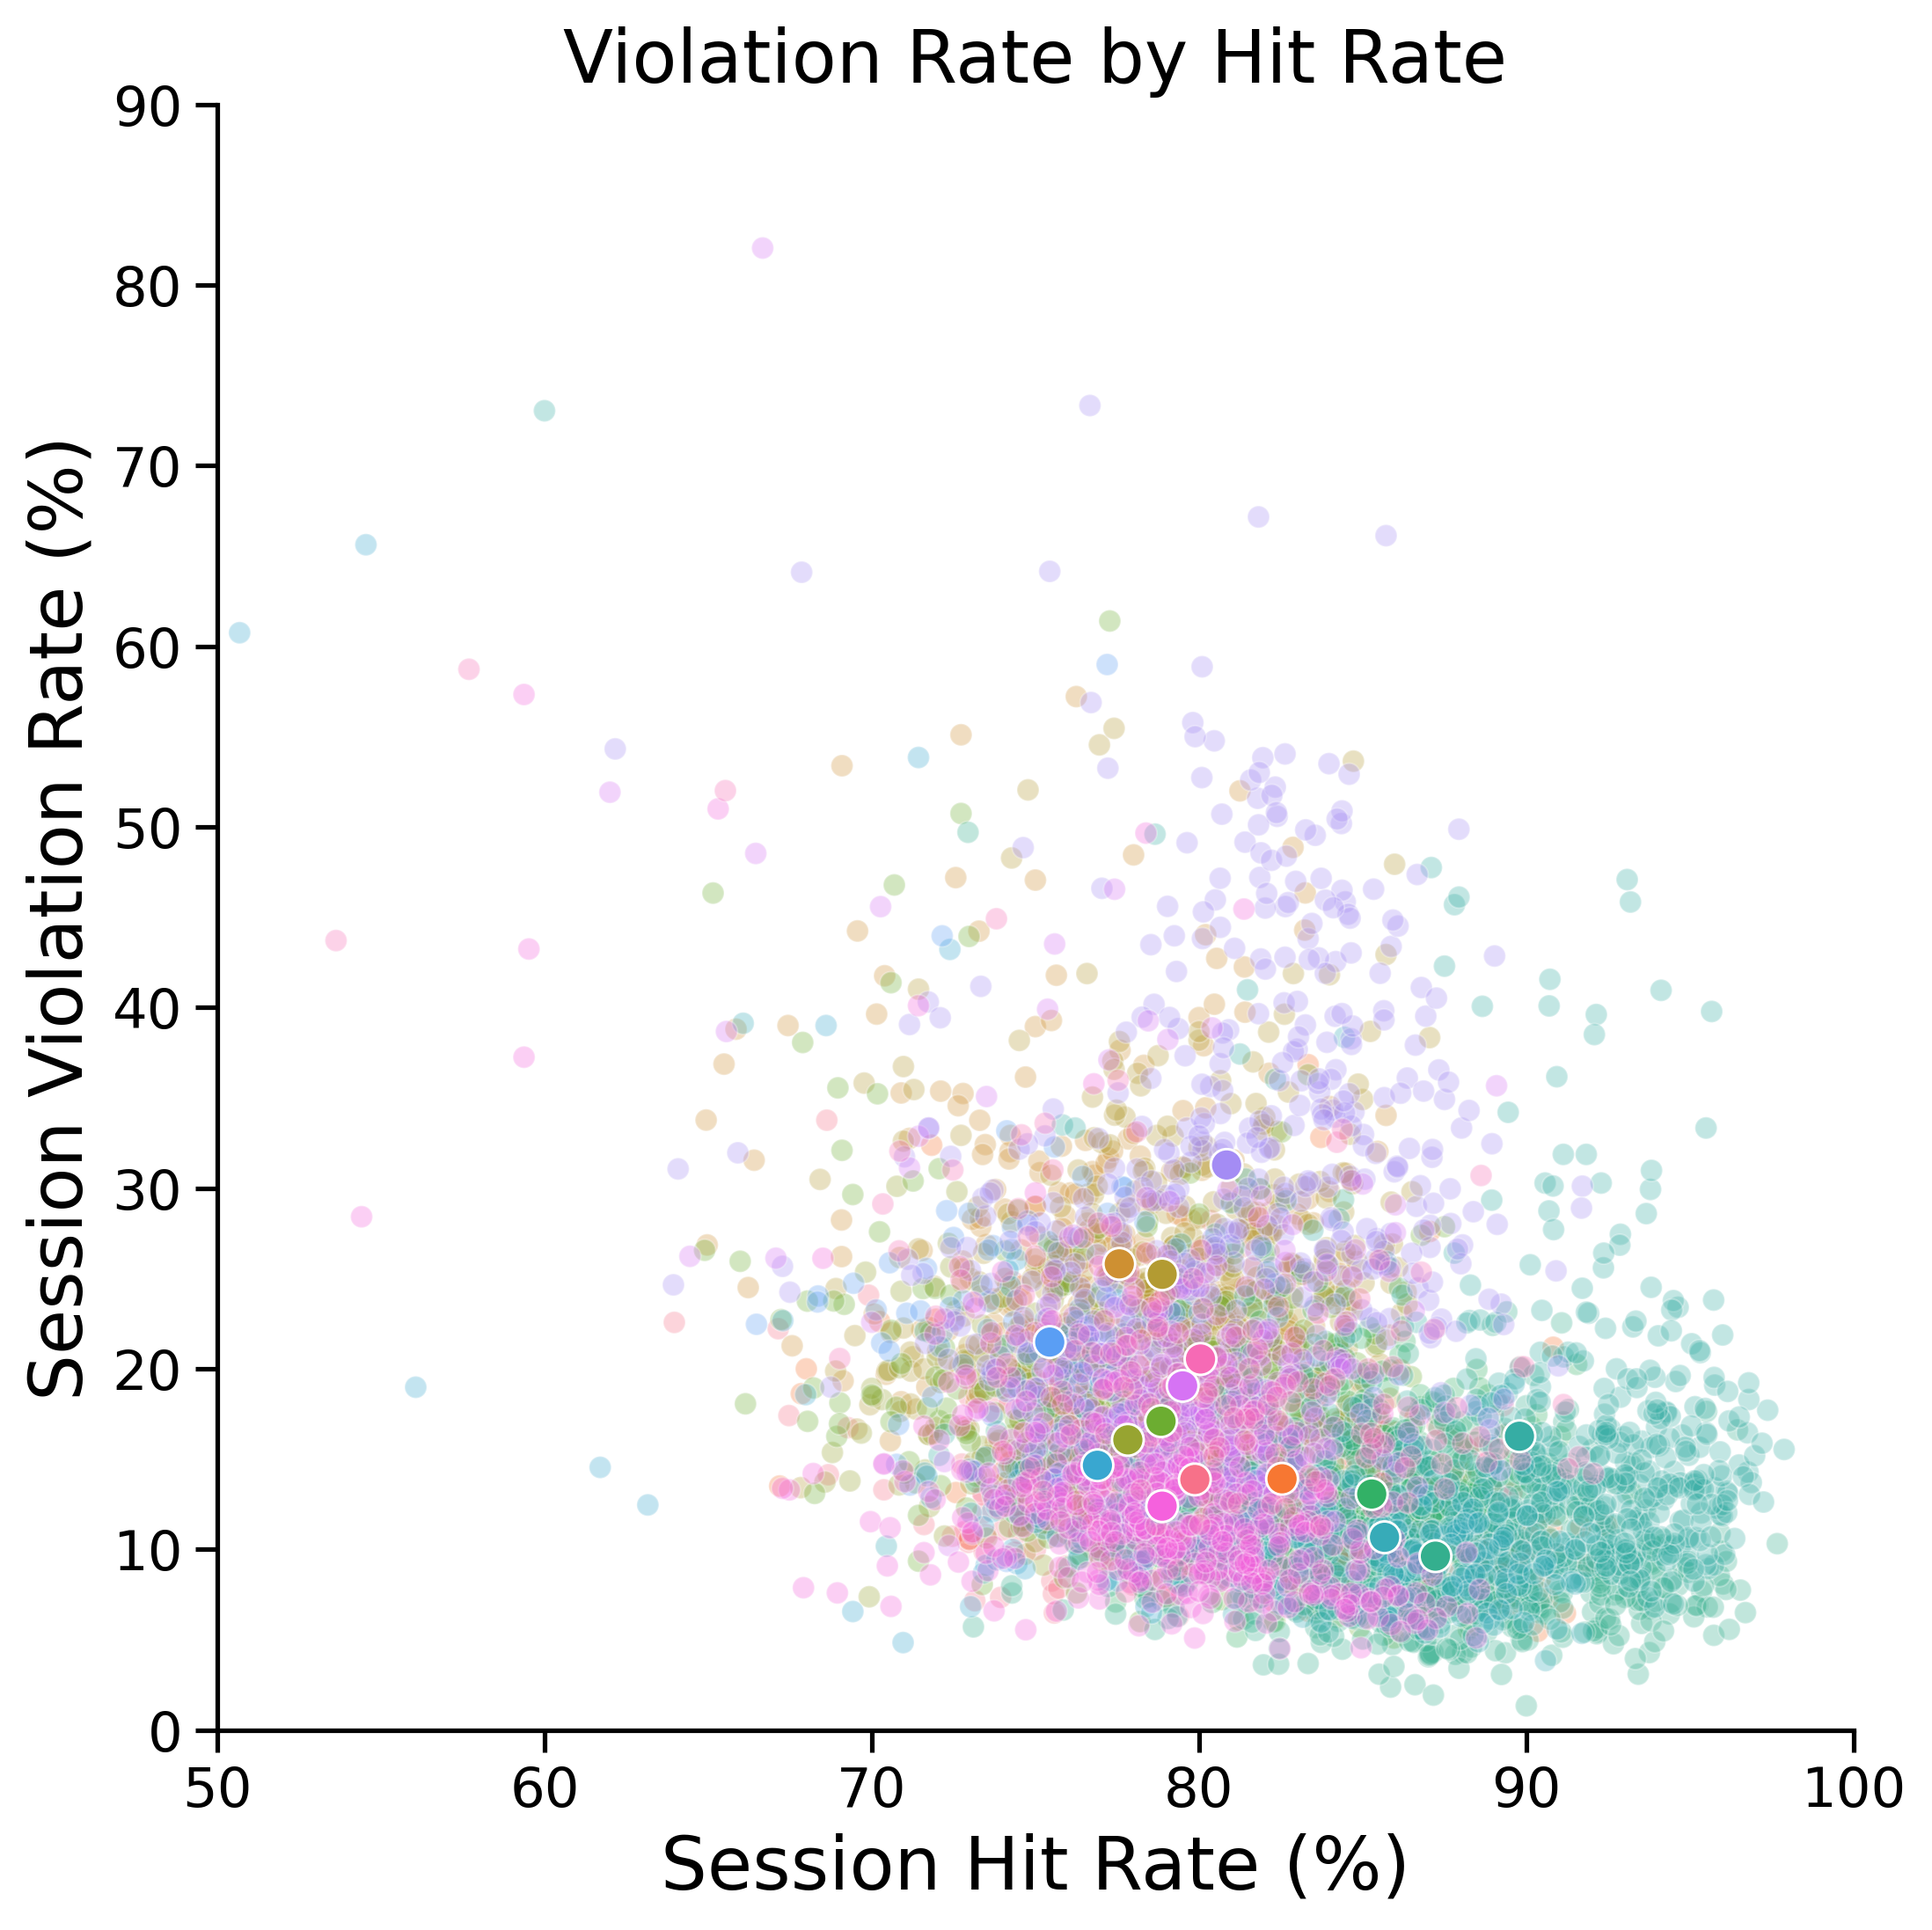

In [3]:
fig, ax = plt.subplots(figsize=(8, 8))
sns.scatterplot(
    data=hit_violation_sessions,
    x="hit_rate",
    y="viol_rate",
    hue="animal_id",
    palette=palette,
    alpha=0.3,
    legend=False,
    ax=ax,
)
sns.scatterplot(
    data=hit_violation_animals,
    x="hit_rate",
    y="viol_rate",
    hue="animal_id",
    palette=palette,
    s=75,
    legend=False,
    ax=ax,
)
ax.set(
    xlabel="Session Hit Rate (%)",
    ylabel="Session Violation Rate (%)",
    xlim=(50, 100),
    ylim=(0, 90),
    title="Violation Rate by Hit Rate",
)
sns.despine(ax=ax)

print(hit_violation_statistics["mixedlm_summary"])
print(
    f"Conditional R² = {hit_violation_statistics['conditional_r2']:.3f}; "
    f"marginal R² = {hit_violation_statistics['marginal_r2']:.3f}"
)

## Trained hit rate vs. violation rate — animals

One point per animal with the OLS fit across animals (the submitted R² = 0.19).

[Text(0.5, 0, 'Average Session Hit Rate (%)'),
 Text(0, 0.5, 'Average Session Violation Rate (%)'),
 (70.0, 100.0),
 (0.0, 55.0),
 Text(0.5, 1.0, 'Aggregated Violation Rate by Hit Rate')]

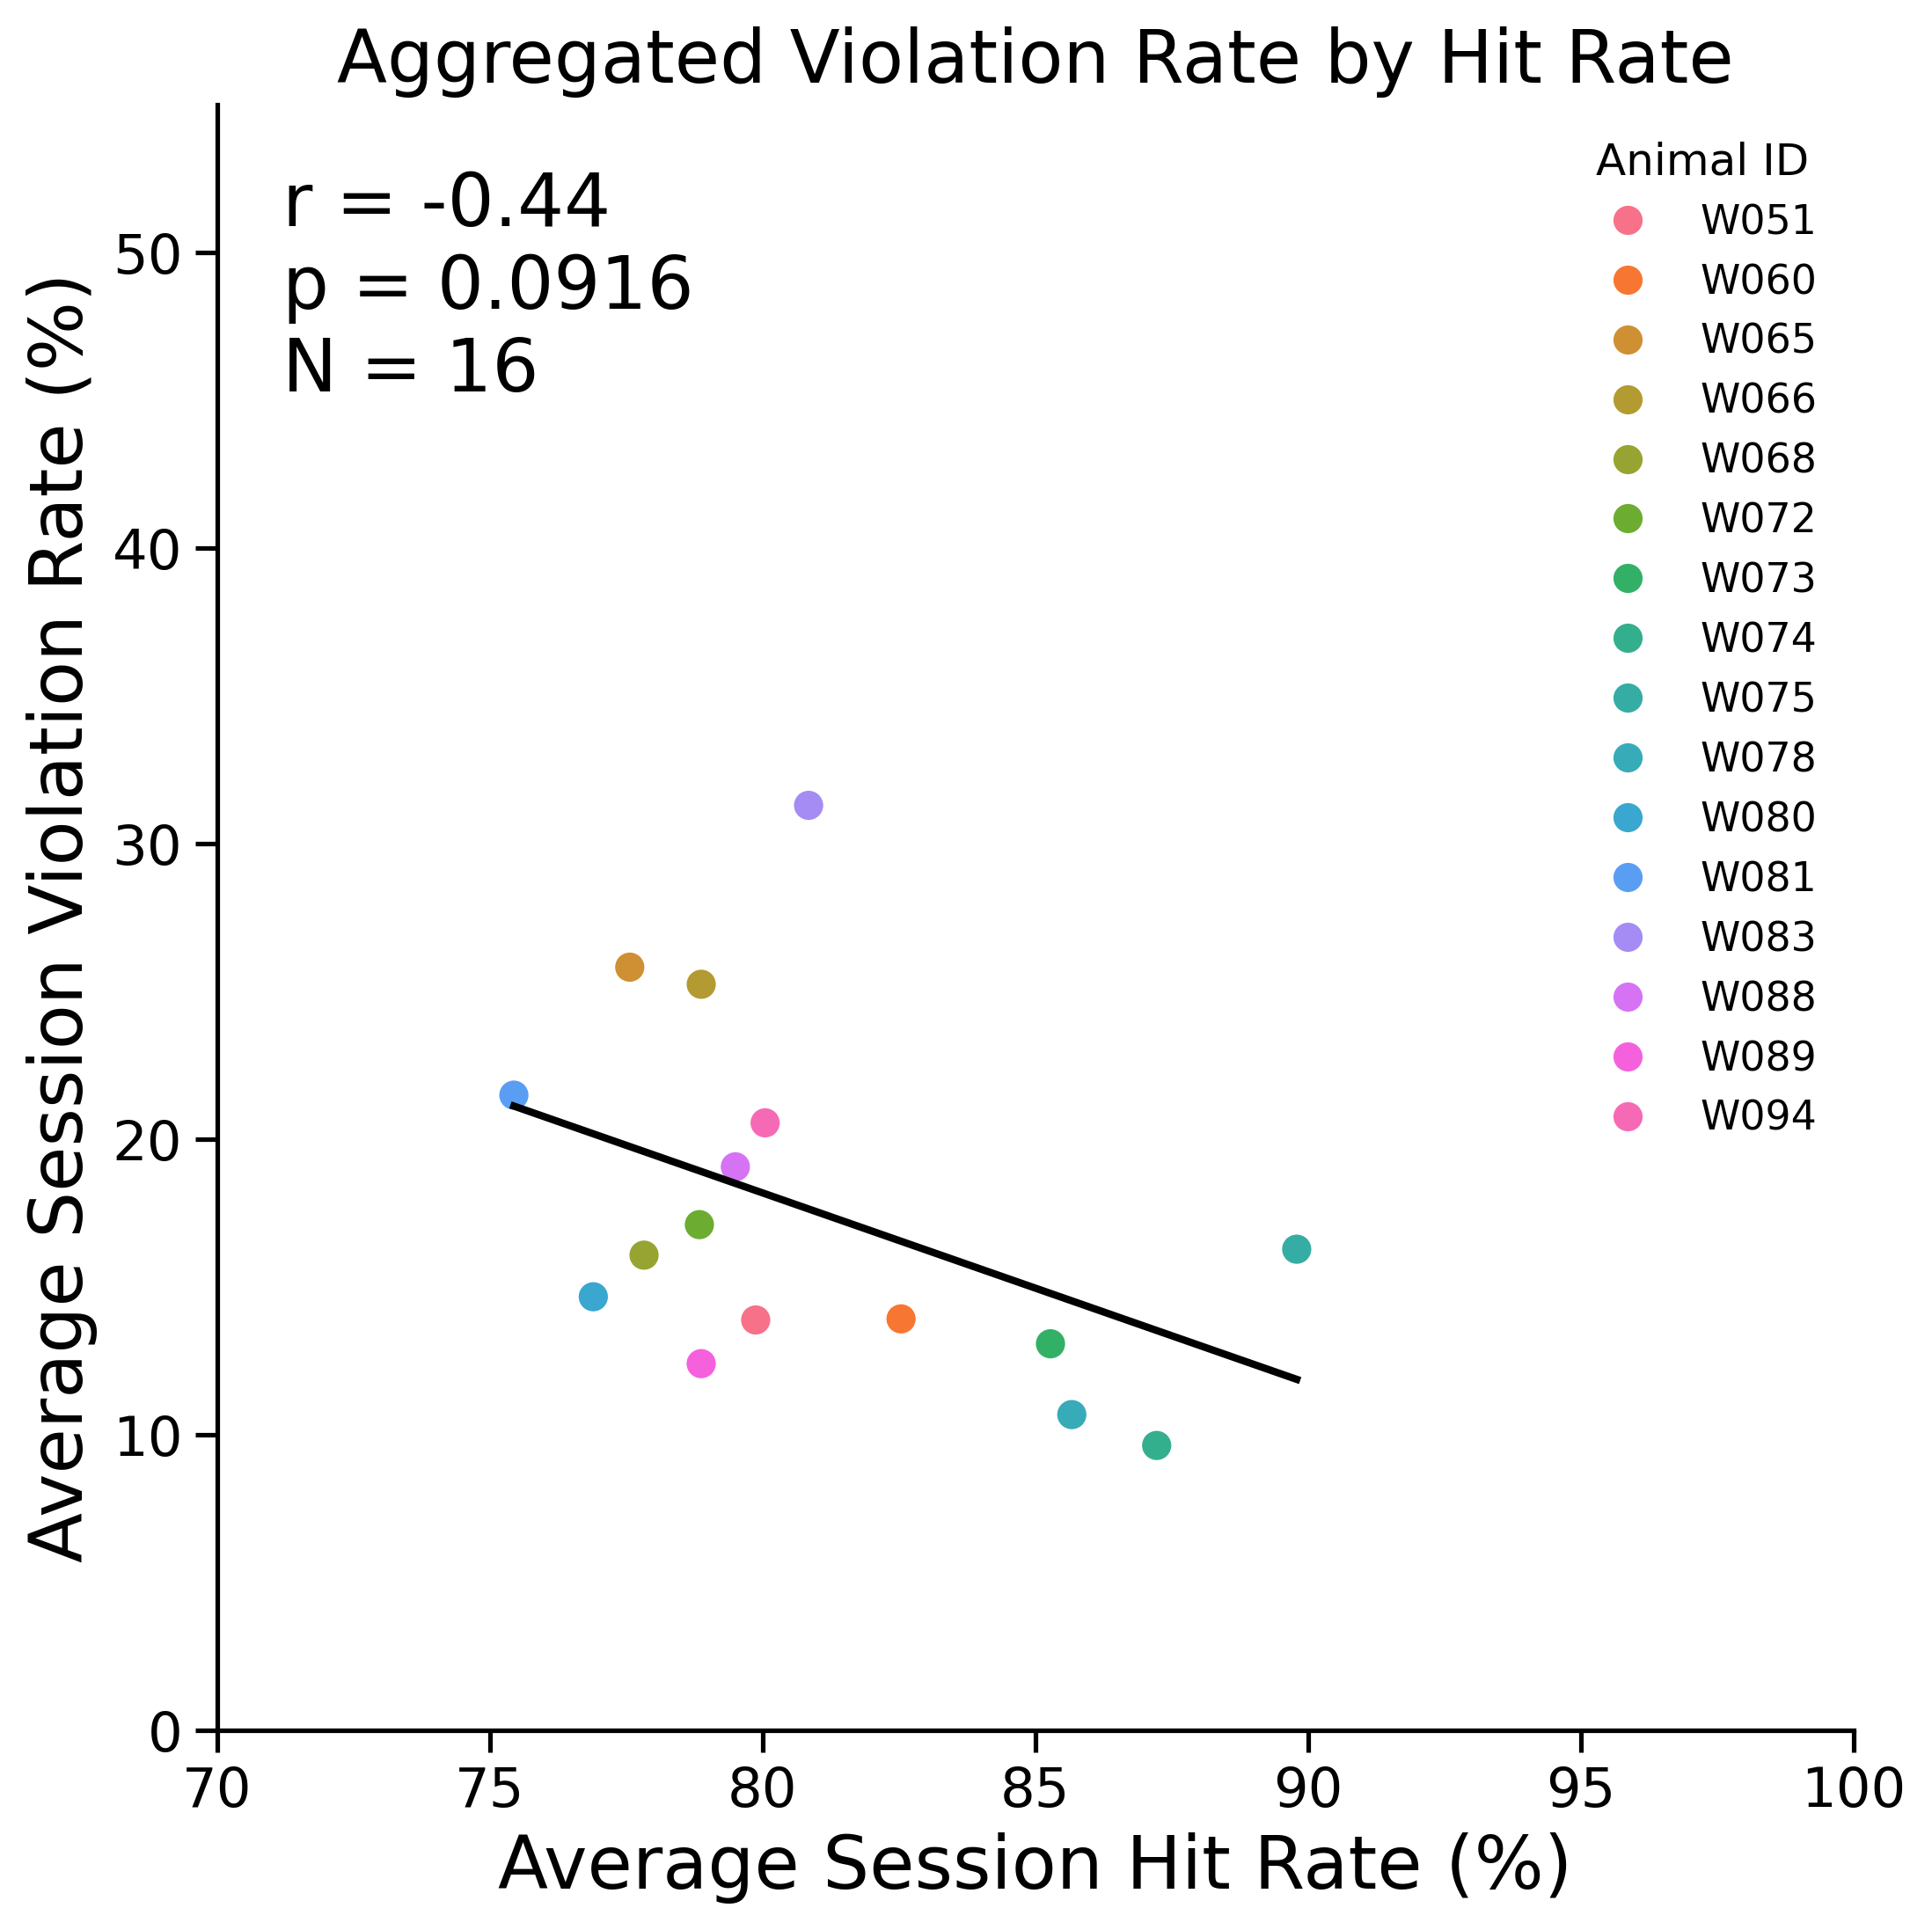

In [4]:
fig, ax = plt.subplots(figsize=(8, 8))
animal_association_scatter(
    ax,
    training_predictors,
    "trained_hit_rate",
    "trained_viol_rate",
    training_statistics["trained_hit_rate"],
    palette=palette,
    legend=True,
)
ax.set(
    xlabel="Average Session Hit Rate (%)",
    ylabel="Average Session Violation Rate (%)",
    xlim=(70, 100),
    ylim=(0, 55),
    title="Aggregated Violation Rate by Hit Rate",
)

## Fixation-stage violation rate vs. trained violation rate

Stage 1 (Grow Nose Poke) is the stage in which center-port fixation grows from 10 ms to ~8 s.

[Text(0.5, 0, 'Fix Grow Stage 1 Violation Rate (%)'),
 Text(0, 0.5, 'Trained Violation Rate (%)'),
 Text(0.5, 1.0, 'Fixation-Stage Violations'),
 (0.0, 50.0),
 (0.0, 50.0)]

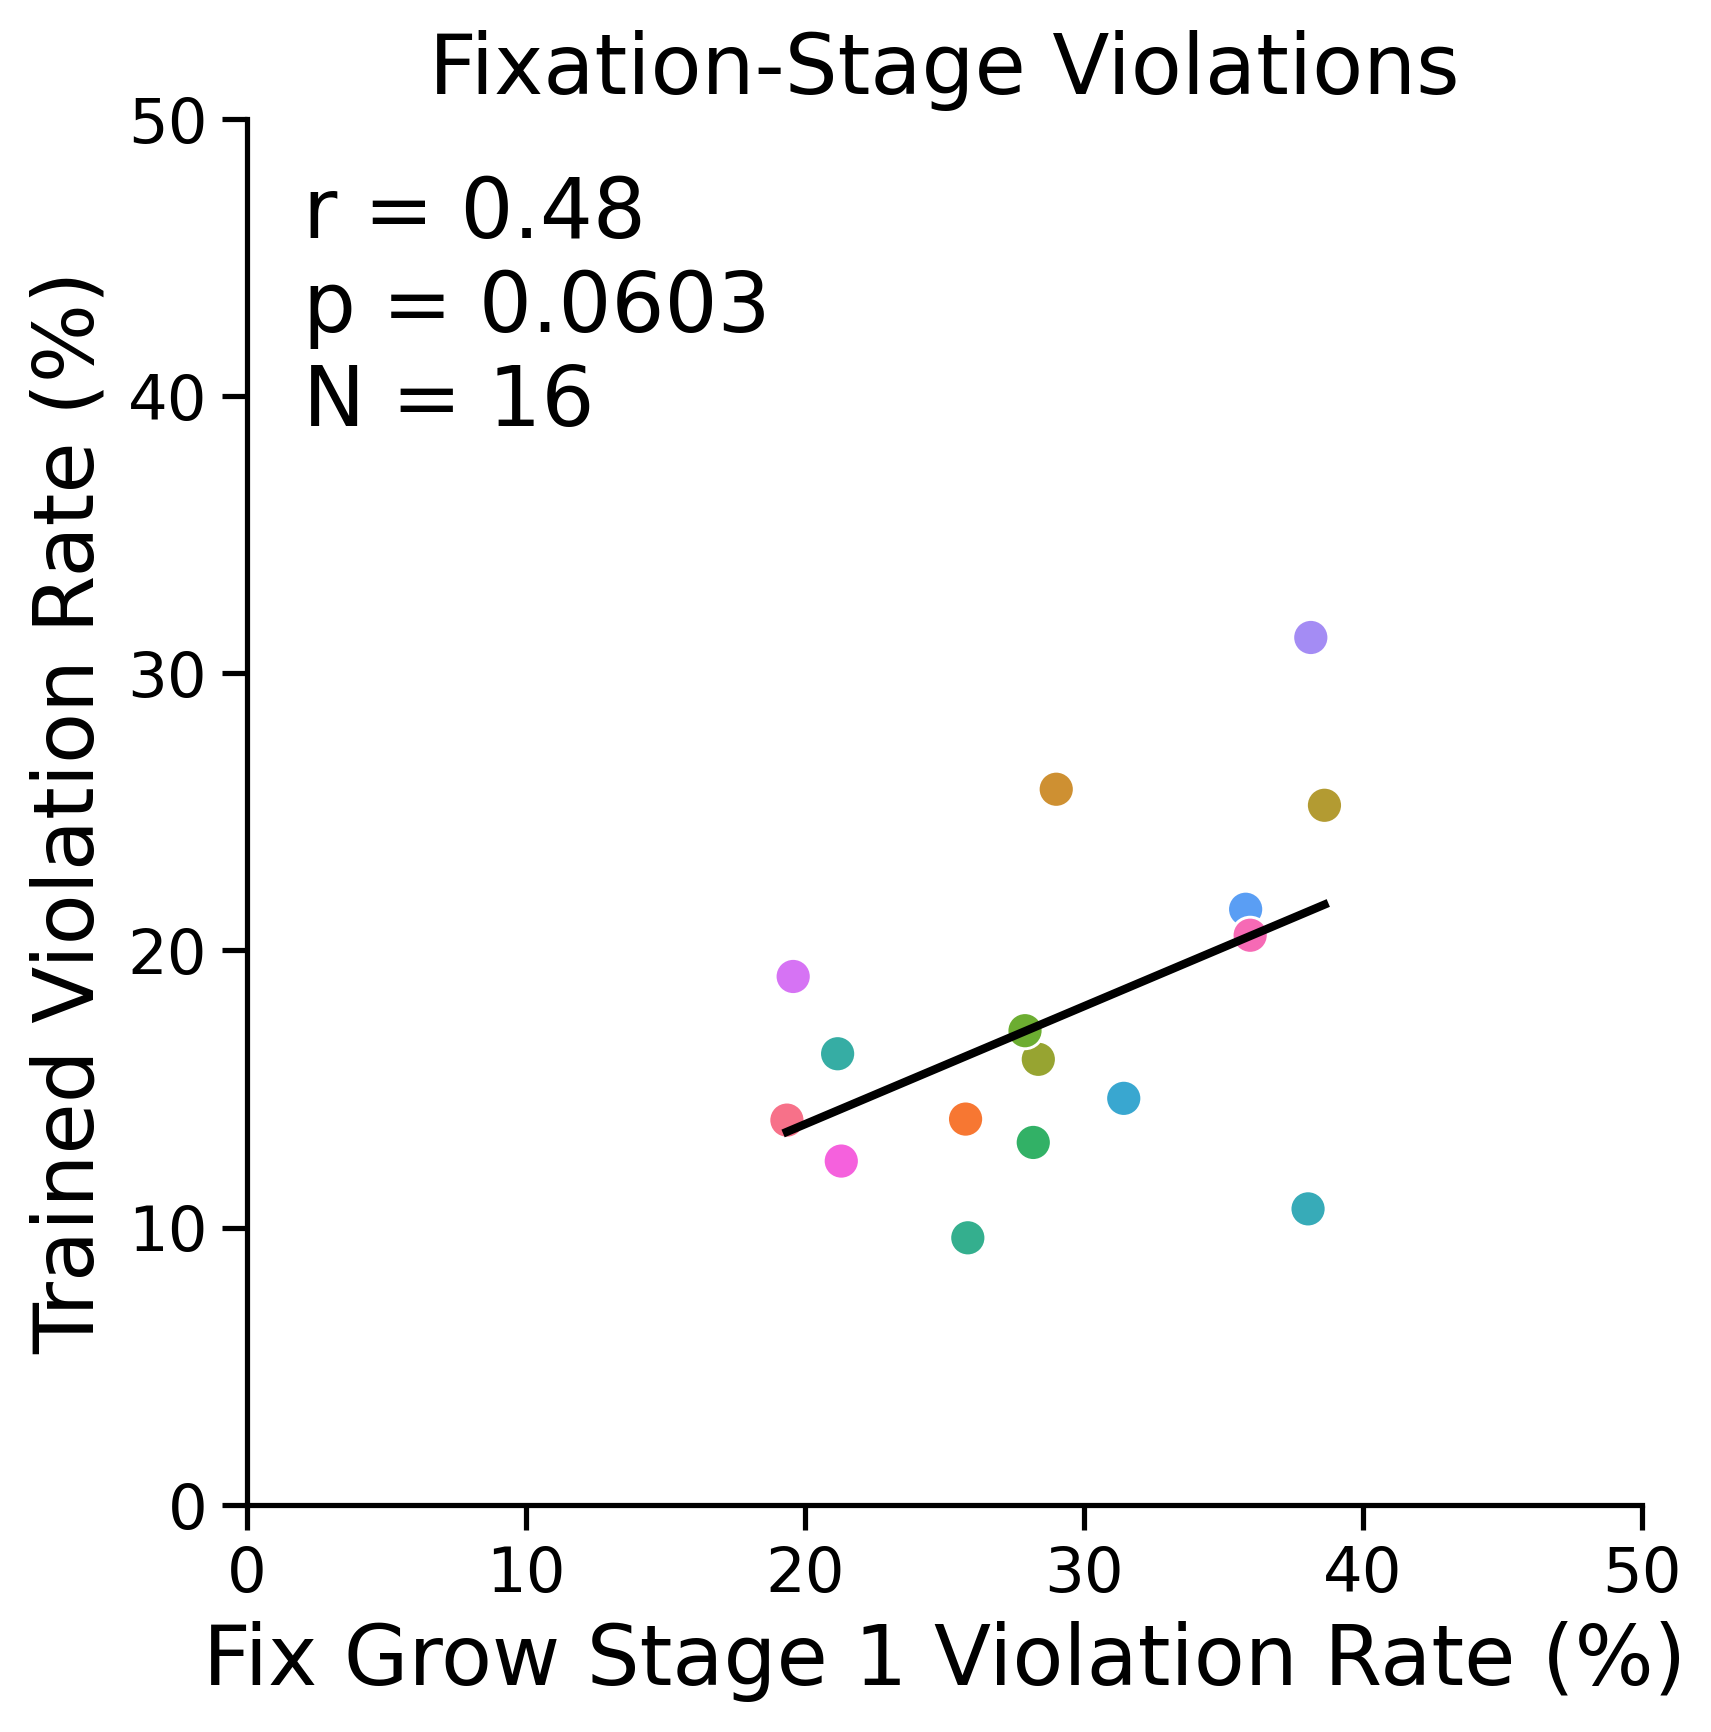

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
animal_association_scatter(
    ax,
    training_predictors,
    "fixation_stage_viol_rate",
    "trained_viol_rate",
    training_statistics["fixation_stage_viol_rate"],
    palette=palette,
)
ax.set(
    xlabel="Fix Grow Stage 1 Violation Rate (%)",
    ylabel=trained_viol_label,
    title="Fixation-Stage Violations",
    ylim=(0, 50),
    xlim=(0, 50)
)

## Time in fixation stage vs. trained violation rate

[Text(0.5, 0, 'Sessions in Stage 1'),
 Text(0, 0.5, 'Trained Violation Rate (%)'),
 Text(0.5, 1.0, 'Time in Fixation Stage'),
 (0.0, 50.0),
 (10.0, 40.0)]

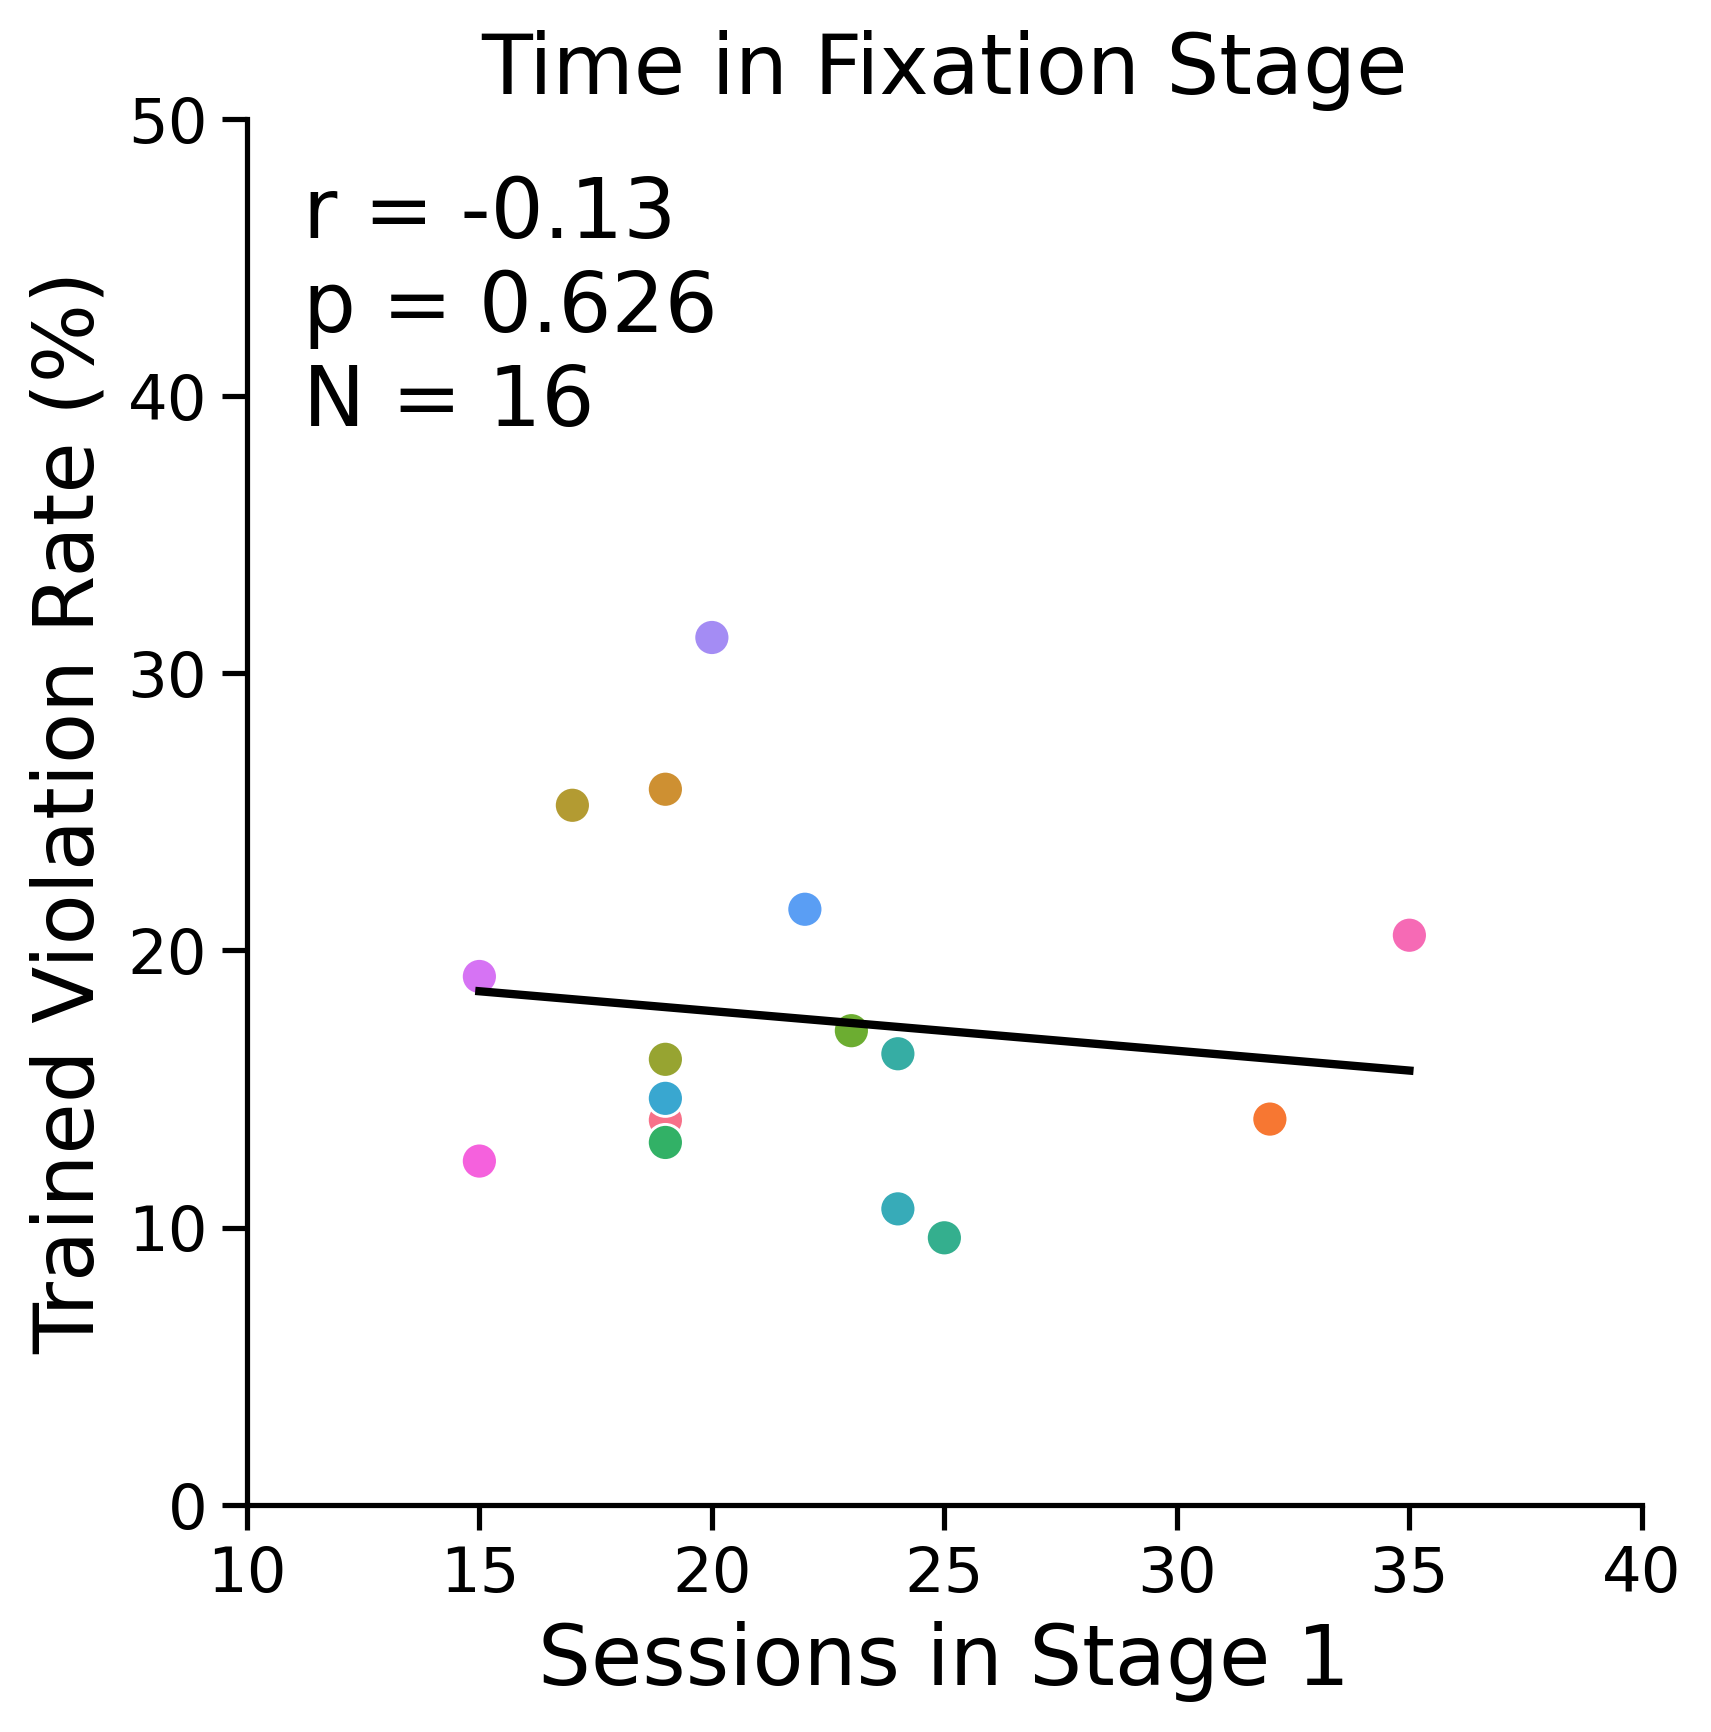

In [6]:
fig, ax = plt.subplots(figsize=(6, 6))
animal_association_scatter(
    ax,
    training_predictors,
    "fixation_stage_sessions",
    "trained_viol_rate",
    training_statistics["fixation_stage_sessions"],
    palette=palette,
)
ax.set(
    xlabel="Sessions in Stage 1",
    ylabel=trained_viol_label,
    title="Time in Fixation Stage",
    ylim=(0, 50),
    xlim=(10, 40)
)

## Time to trained vs. trained violation rate

Time to trained is the session of the last low-to-high crossing of the 72.5% 21-session rolling hit rate (Supporting Figure S3); trained sessions begin after it.

[Text(0.5, 0, 'Sessions to Trained'),
 Text(0, 0.5, 'Trained Violation Rate (%)'),
 Text(0.5, 1.0, 'Time to Trained'),
 (0.0, 50.0)]

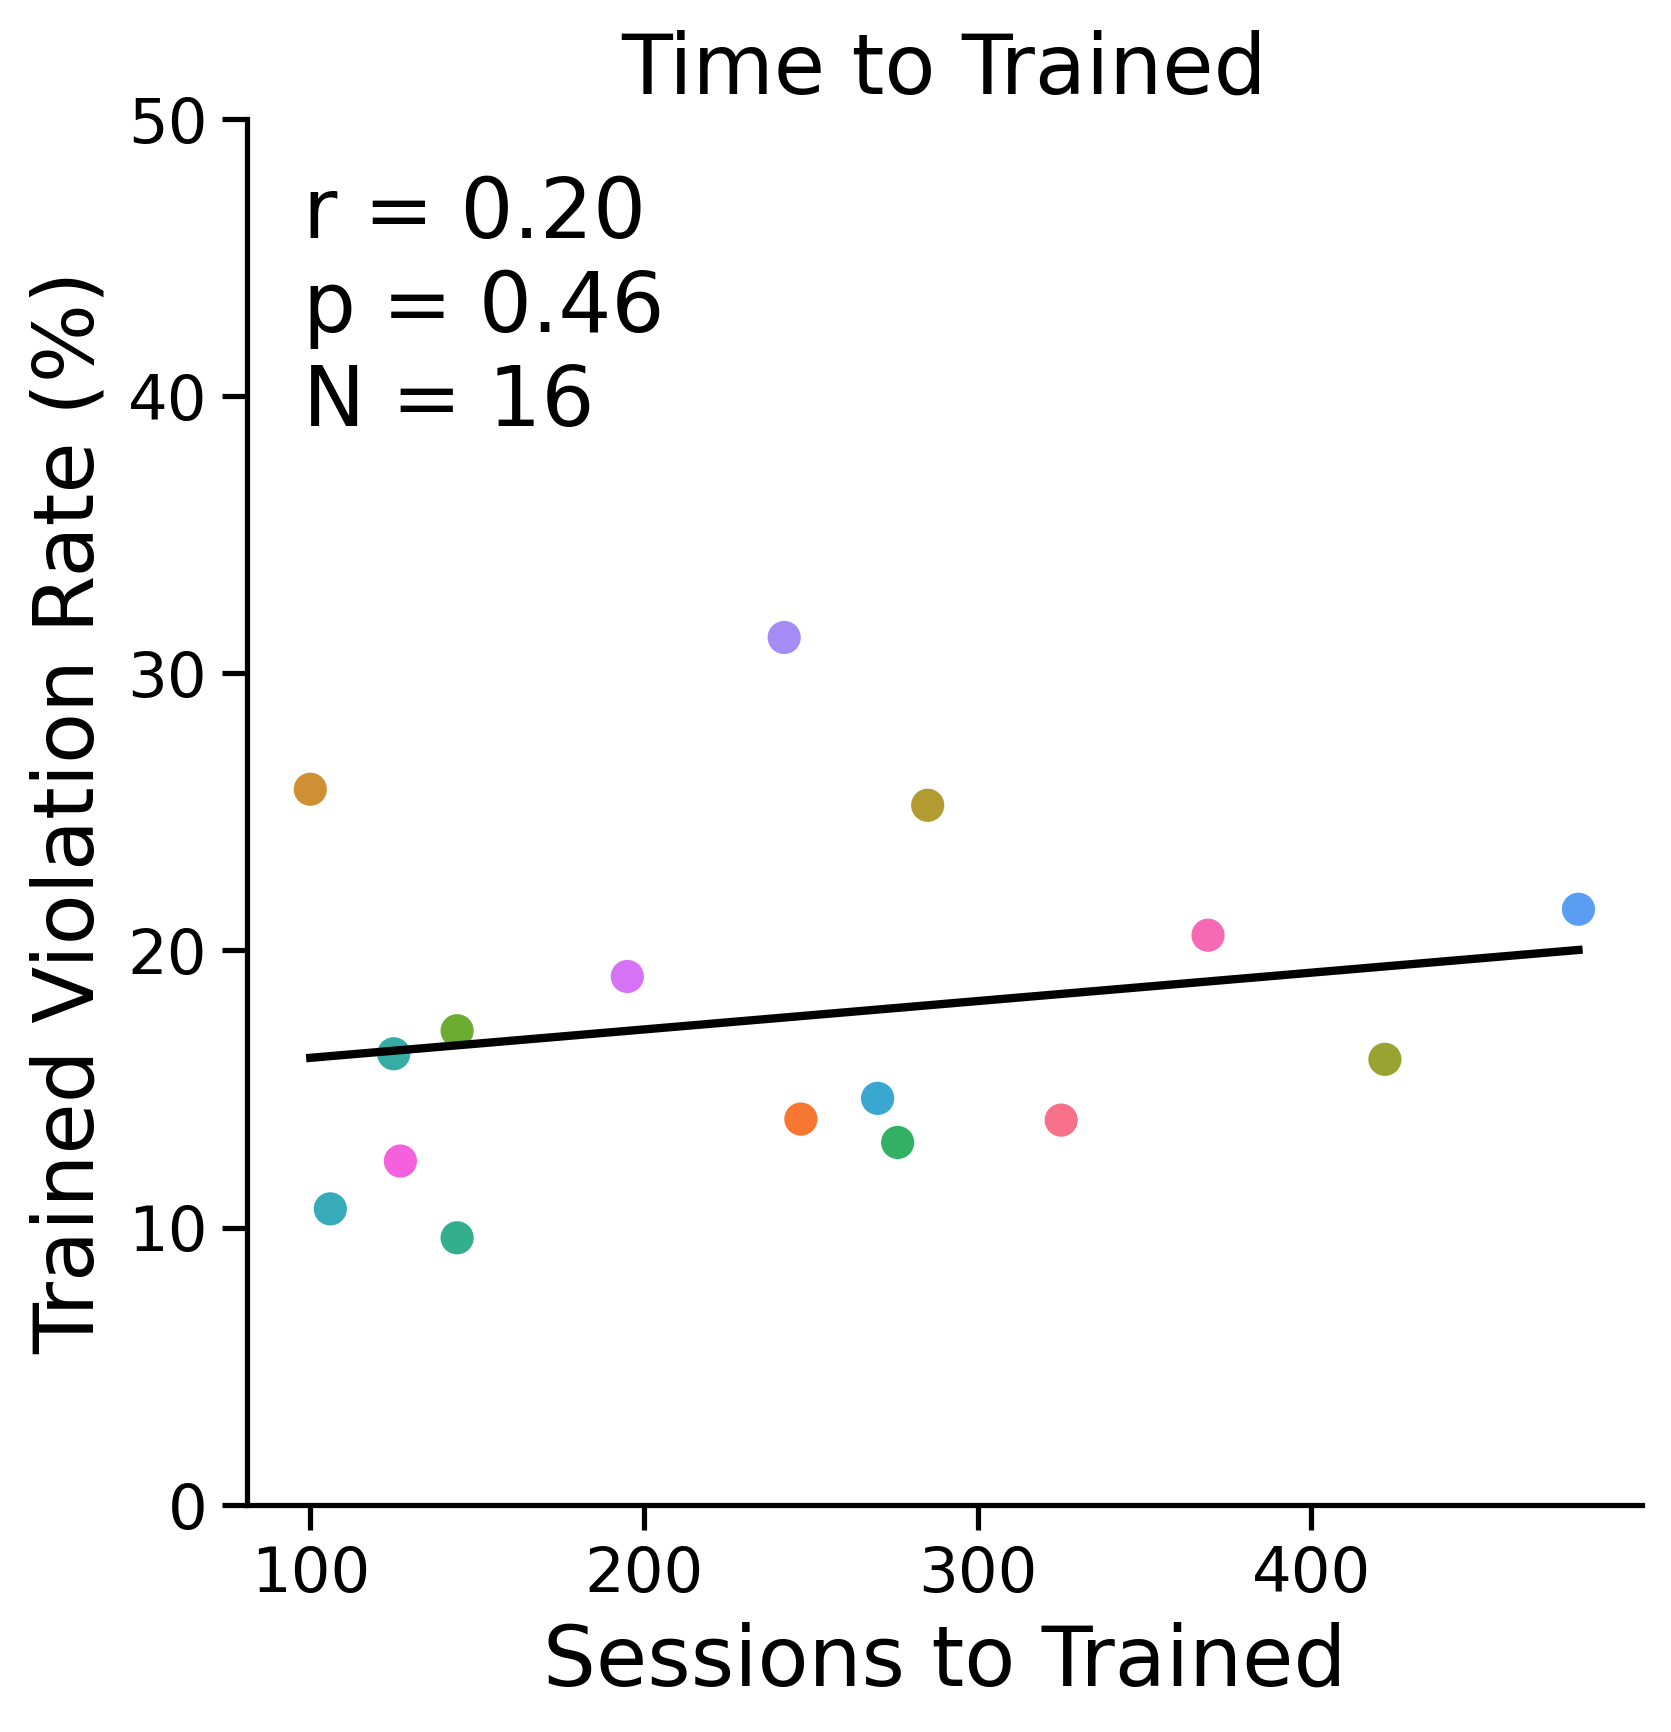

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
animal_association_scatter(
    ax,
    training_predictors,
    "sessions_to_trained",
    "trained_viol_rate",
    training_statistics["sessions_to_trained"],
    palette=palette,
)
ax.set(
    xlabel="Sessions to Trained",
    ylabel=trained_viol_label,
    title="Time to Trained",
    ylim=(0, 50),
)

## Animal-level statistics

Associations with trained violation rate across the 16 animals. These are exploratory and uncorrected for multiple comparisons.

In [8]:
pd.DataFrame(training_statistics).T[
    ["n_animals", "pearson_r", "pearson_p",
        "spearman_r", "spearman_p", "slope", "r2"]
]

,n_animals,pearson_r,pearson_p,spearman_r,spearman_p,slope,r2
fixation_stage_sessions,16,-0.131896,0.626312,-0.124083,0.647064,-0.143095,0.017397
fixation_stage_viol_rate,16,0.47931,0.060301,0.444118,0.084823,0.425509,0.229738
sessions_to_trained,16,0.198789,0.460472,0.189846,0.481291,0.010241,0.039517
trained_hit_rate,16,-0.435665,0.091644,-0.429412,0.096936,-0.644238,0.189804


## Violation rate by delay length

The delay sits inside the required fixation, so longer delays mean longer holds. Only the 2, 3, 4, and 6 s delays are shown (5, 7, and 8 s are used by one or two animals). Not every animal used every delay (N = 16, 15, 15, and 13). Gray lines are individual animals; the colored line is the mean ± SEM across animals. The annotation tests per-animal linear slopes against zero; the table gives paired t-tests of each delay against 2 s (Bonferroni over three comparisons).

,mean_difference,n_animals,p_value,p_value_bonferroni,t
3,0.225148,15.0,0.787620,1.000000,0.274619
4,0.874077,15.0,0.266037,0.798112,1.158509
6,3.716568,13.0,0.001827,0.005482,3.979671


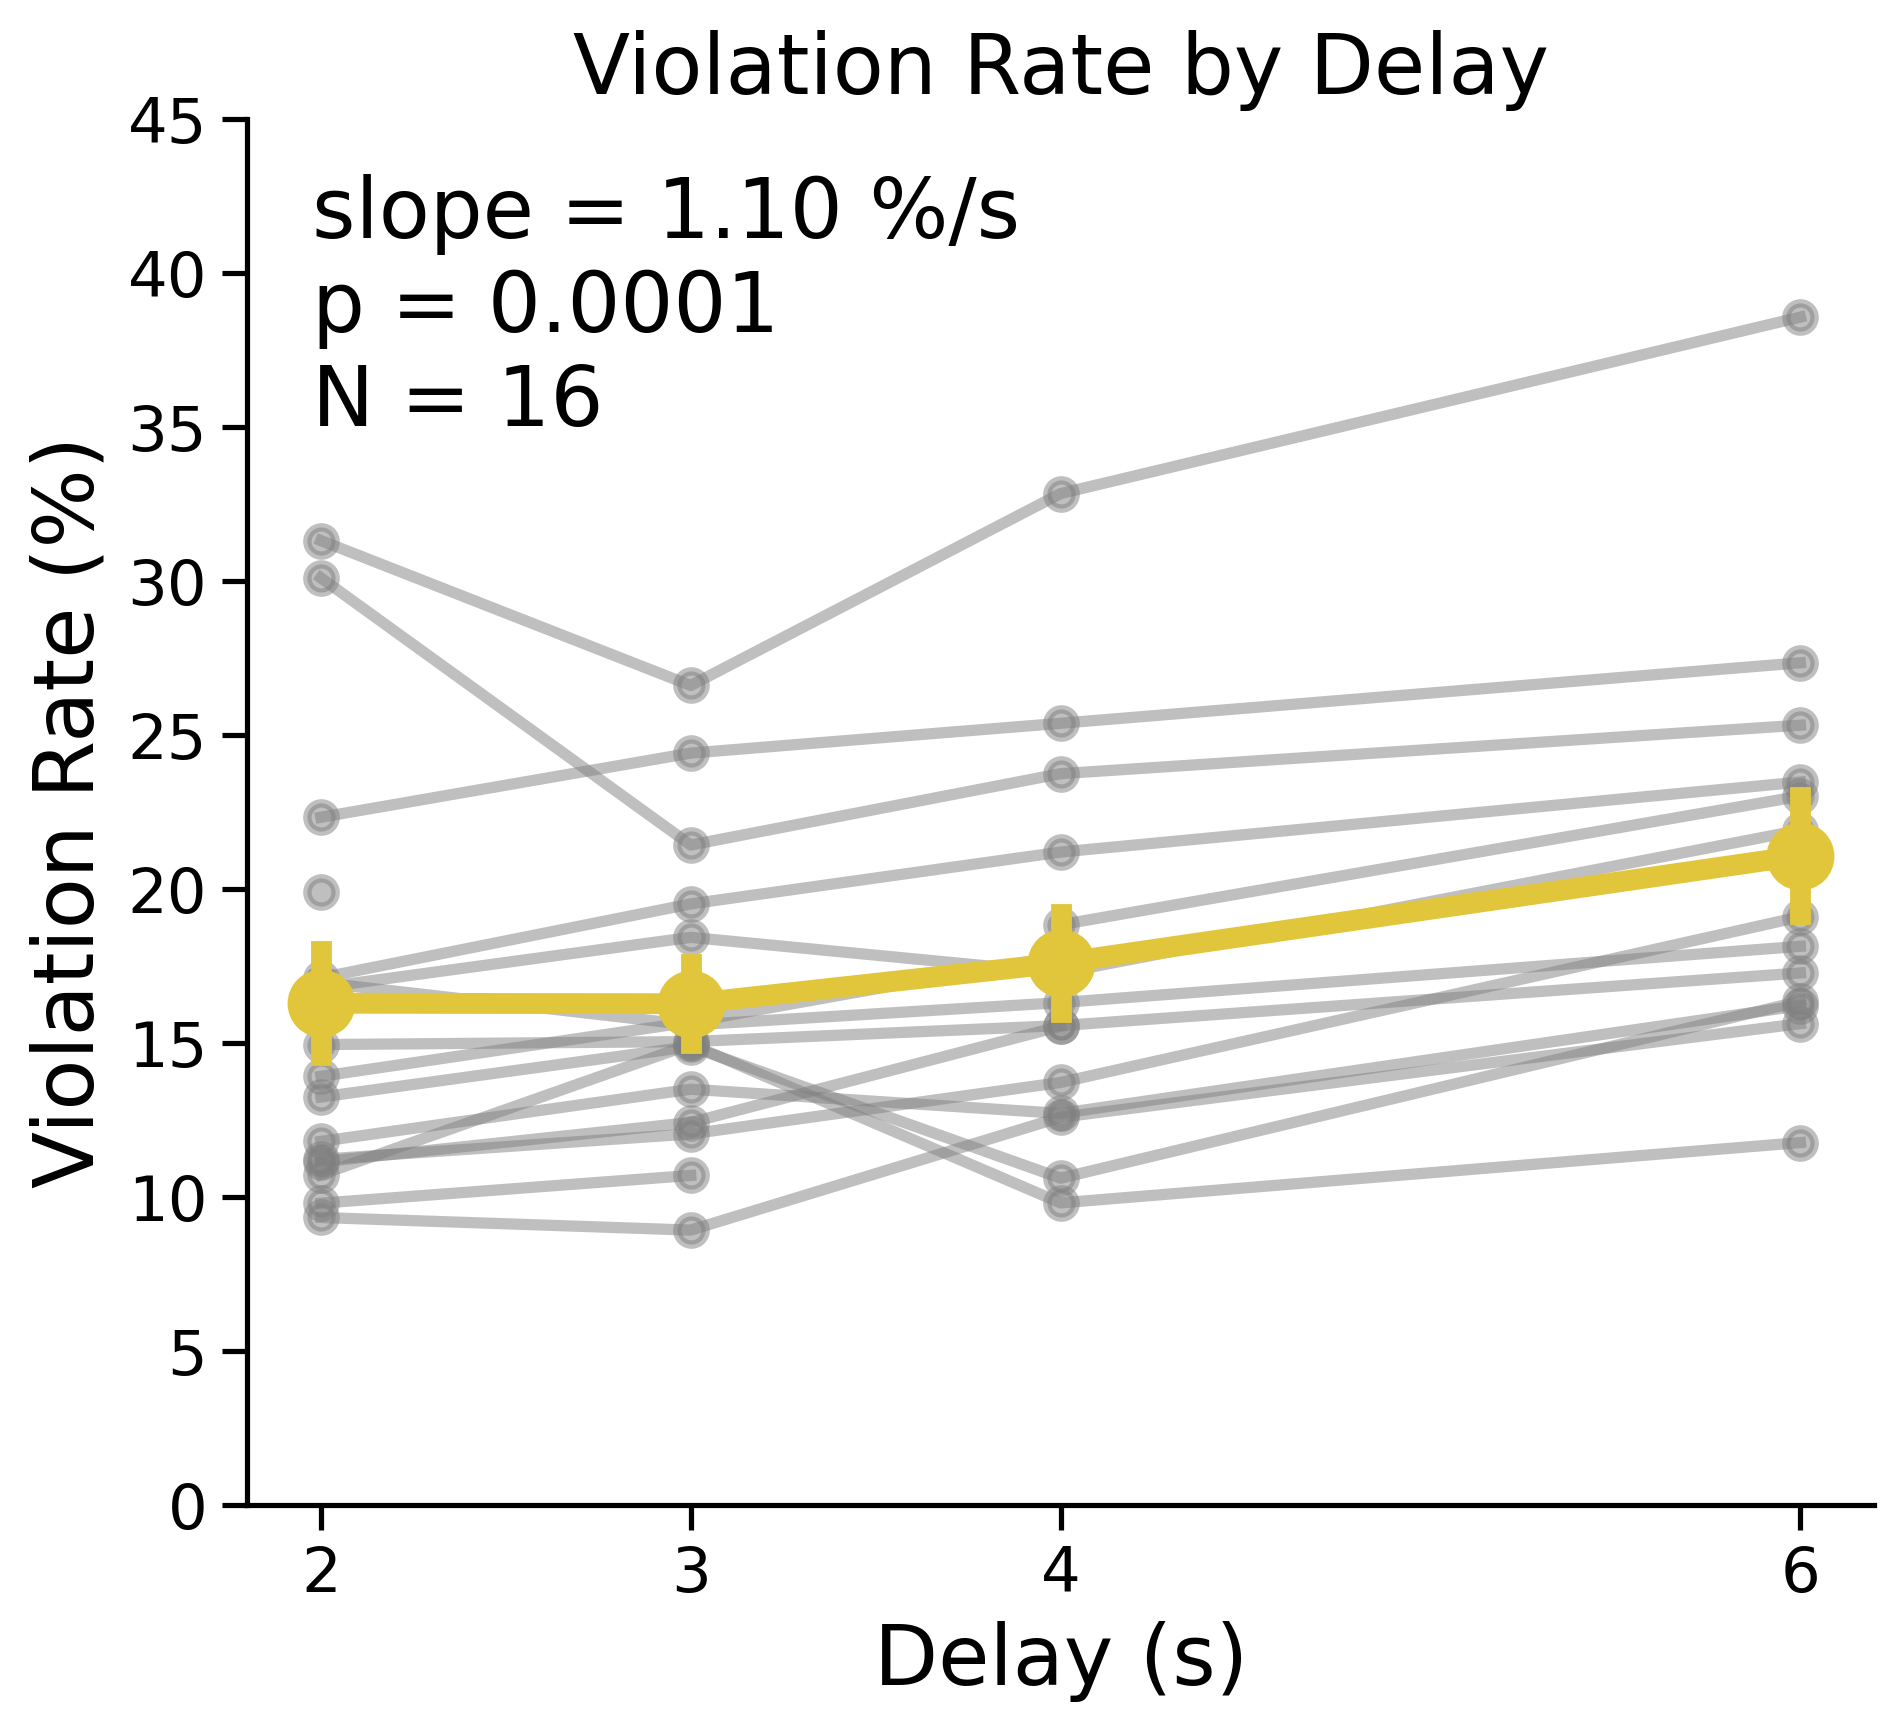

In [ ]:
slope_stats = delay_statistics["delay_length"]["slope"]
fig, ax = plt.subplots(figsize=(7, 6))
sns.pointplot(
    data=delay_rates,
    x="delay_time",
    y="viol_rate",
    hue="animal_id",
    palette=animal_grays,
    alpha=0.5,
    native_scale=True,
    legend=False,
    ax=ax,
)
sns.pointplot(
    data=delay_rates,
    x="delay_time",
    y="viol_rate",
    color=VIOLATION_COLOR,
    errorbar="se",
    linewidth=5,
    native_scale=True,
    ax=ax,
)
ax.text(
    0.04,
    0.96,
    f"slope = {slope_stats['mean_slope']:.2f} %/s\n"
    f"p = {slope_stats['p_value']:.2g}\n"
    f"N = {slope_stats['n_animals']}",
    transform=ax.transAxes,
    va="top",
)
ax.set(
    xticks=TRAINED_DELAYS,
    xlabel="Delay (s)",
    ylabel="Violation Rate (%)",
    title="Violation Rate by Delay",
    ylim=(0, 45)

)
sns.despine(ax=ax)

pd.DataFrame(delay_statistics["delay_length"]["versus_reference"]).T

## Violation rate by delay relative to the previous trial

Each trial is labeled by whether its delay is longer than, or the same as or shorter than, the previous trial's delay in the same session; the first trial of each session is excluded. The previous trial's scheduled delay is used even when that trial was a violation. Gray lines are individual animals; the colored line is the mean ± SEM. The annotation is a paired t-test across animals.

Longer-than-previous trials also have longer absolute delays on average (a 2 s trial can never be longer than the one before), so this comparison is confounded with delay length. The next section controls for it.

Mean current delay: same or shorter = 3.05 s; longer = 4.55 s


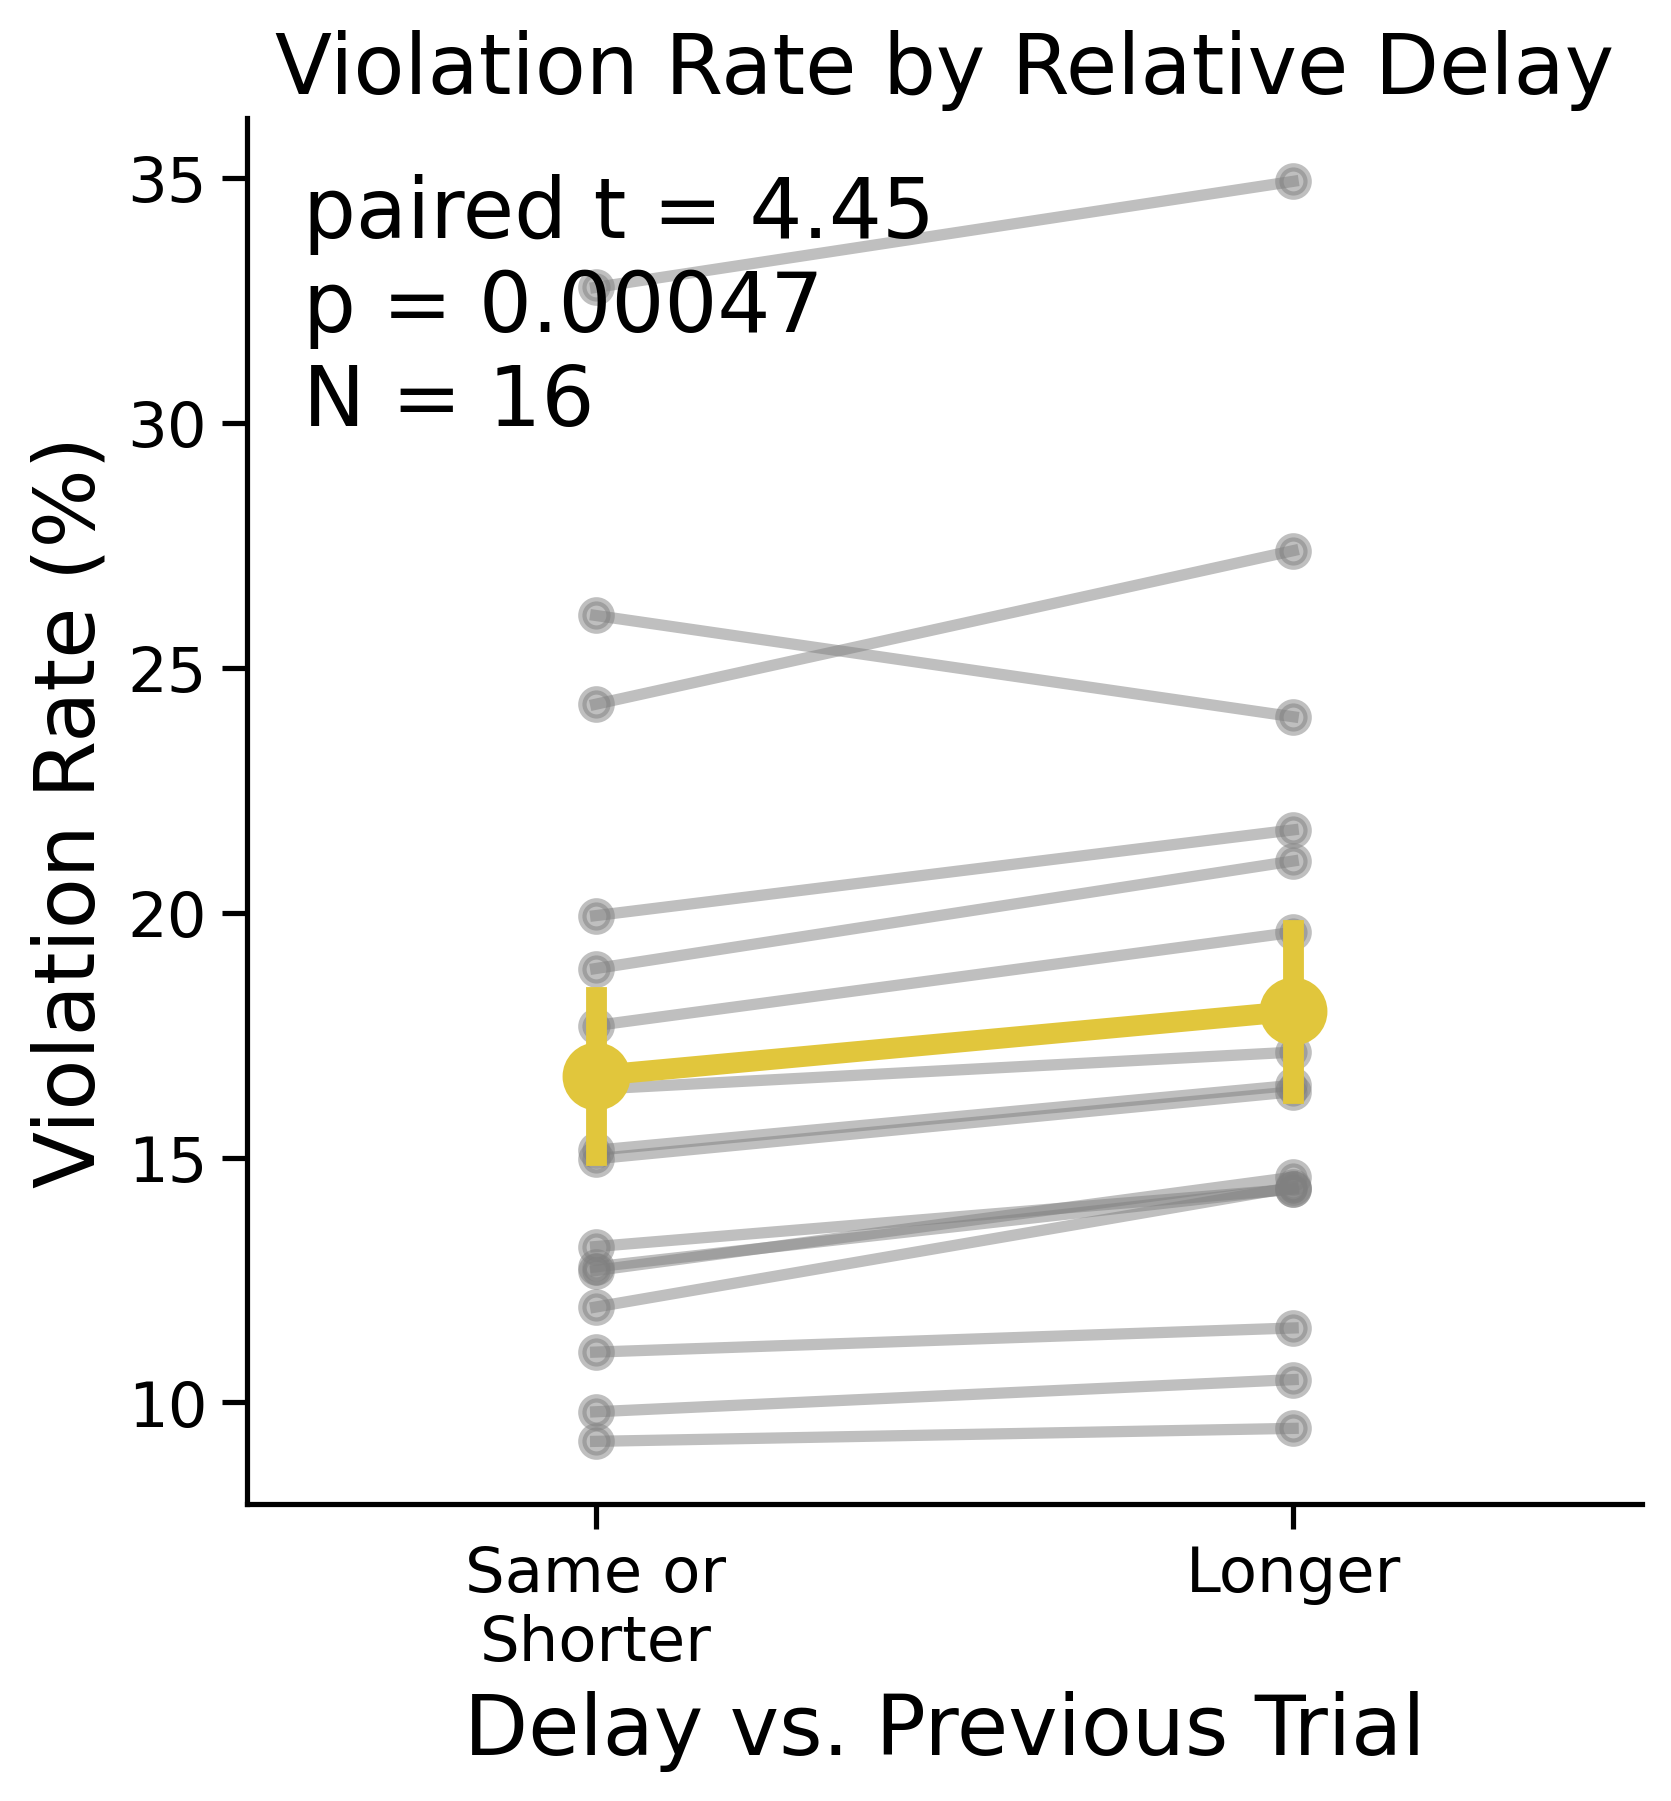

In [ ]:
relative_stats = delay_statistics["relative_delay"]["unmatched"]
fig, ax = plt.subplots(figsize=(6, 6))
sns.pointplot(
    data=relative_rates,
    x="relative_delay",
    y="viol_rate",
    order=RELATIVE_DELAY_ORDER,
    hue="animal_id",
    palette=animal_grays,
    alpha=0.5,
    legend=False,
    ax=ax,
)
sns.pointplot(
    data=relative_rates,
    x="relative_delay",
    y="viol_rate",
    order=RELATIVE_DELAY_ORDER,
    color=VIOLATION_COLOR,
    errorbar="se",
    linewidth=5,
    ax=ax,
)
ax.text(
    0.04,
    0.96,
    f"paired t = {relative_stats['t']:.2f}\n"
    f"p = {relative_stats['p_value']:.2g}\n"
    f"N = {relative_stats['n_animals']}",
    transform=ax.transAxes,
    va="top",
)
ax.set_xticks(range(2), ["Same or\nShorter", "Longer"])
ax.set(
    xlabel="Delay vs. Previous Trial",
    ylabel="Violation Rate (%)",
    title="Violation Rate by Relative Delay",
)
sns.despine(ax=ax)

print(
    f"Mean current delay: same or shorter = "
    f"{relative_stats['mean_delay_same_or_shorter']:.2f} s; "
    f"longer = {relative_stats['mean_delay_longer']:.2f} s"
)

## Relative delay matched on current delay

The same split, shown separately for each current delay (2 s is omitted because it can never be longer than the previous delay). Points are mean ± SEM across animals. The annotation tests the longer minus same-or-shorter difference, averaged over current delays within each animal, against zero.

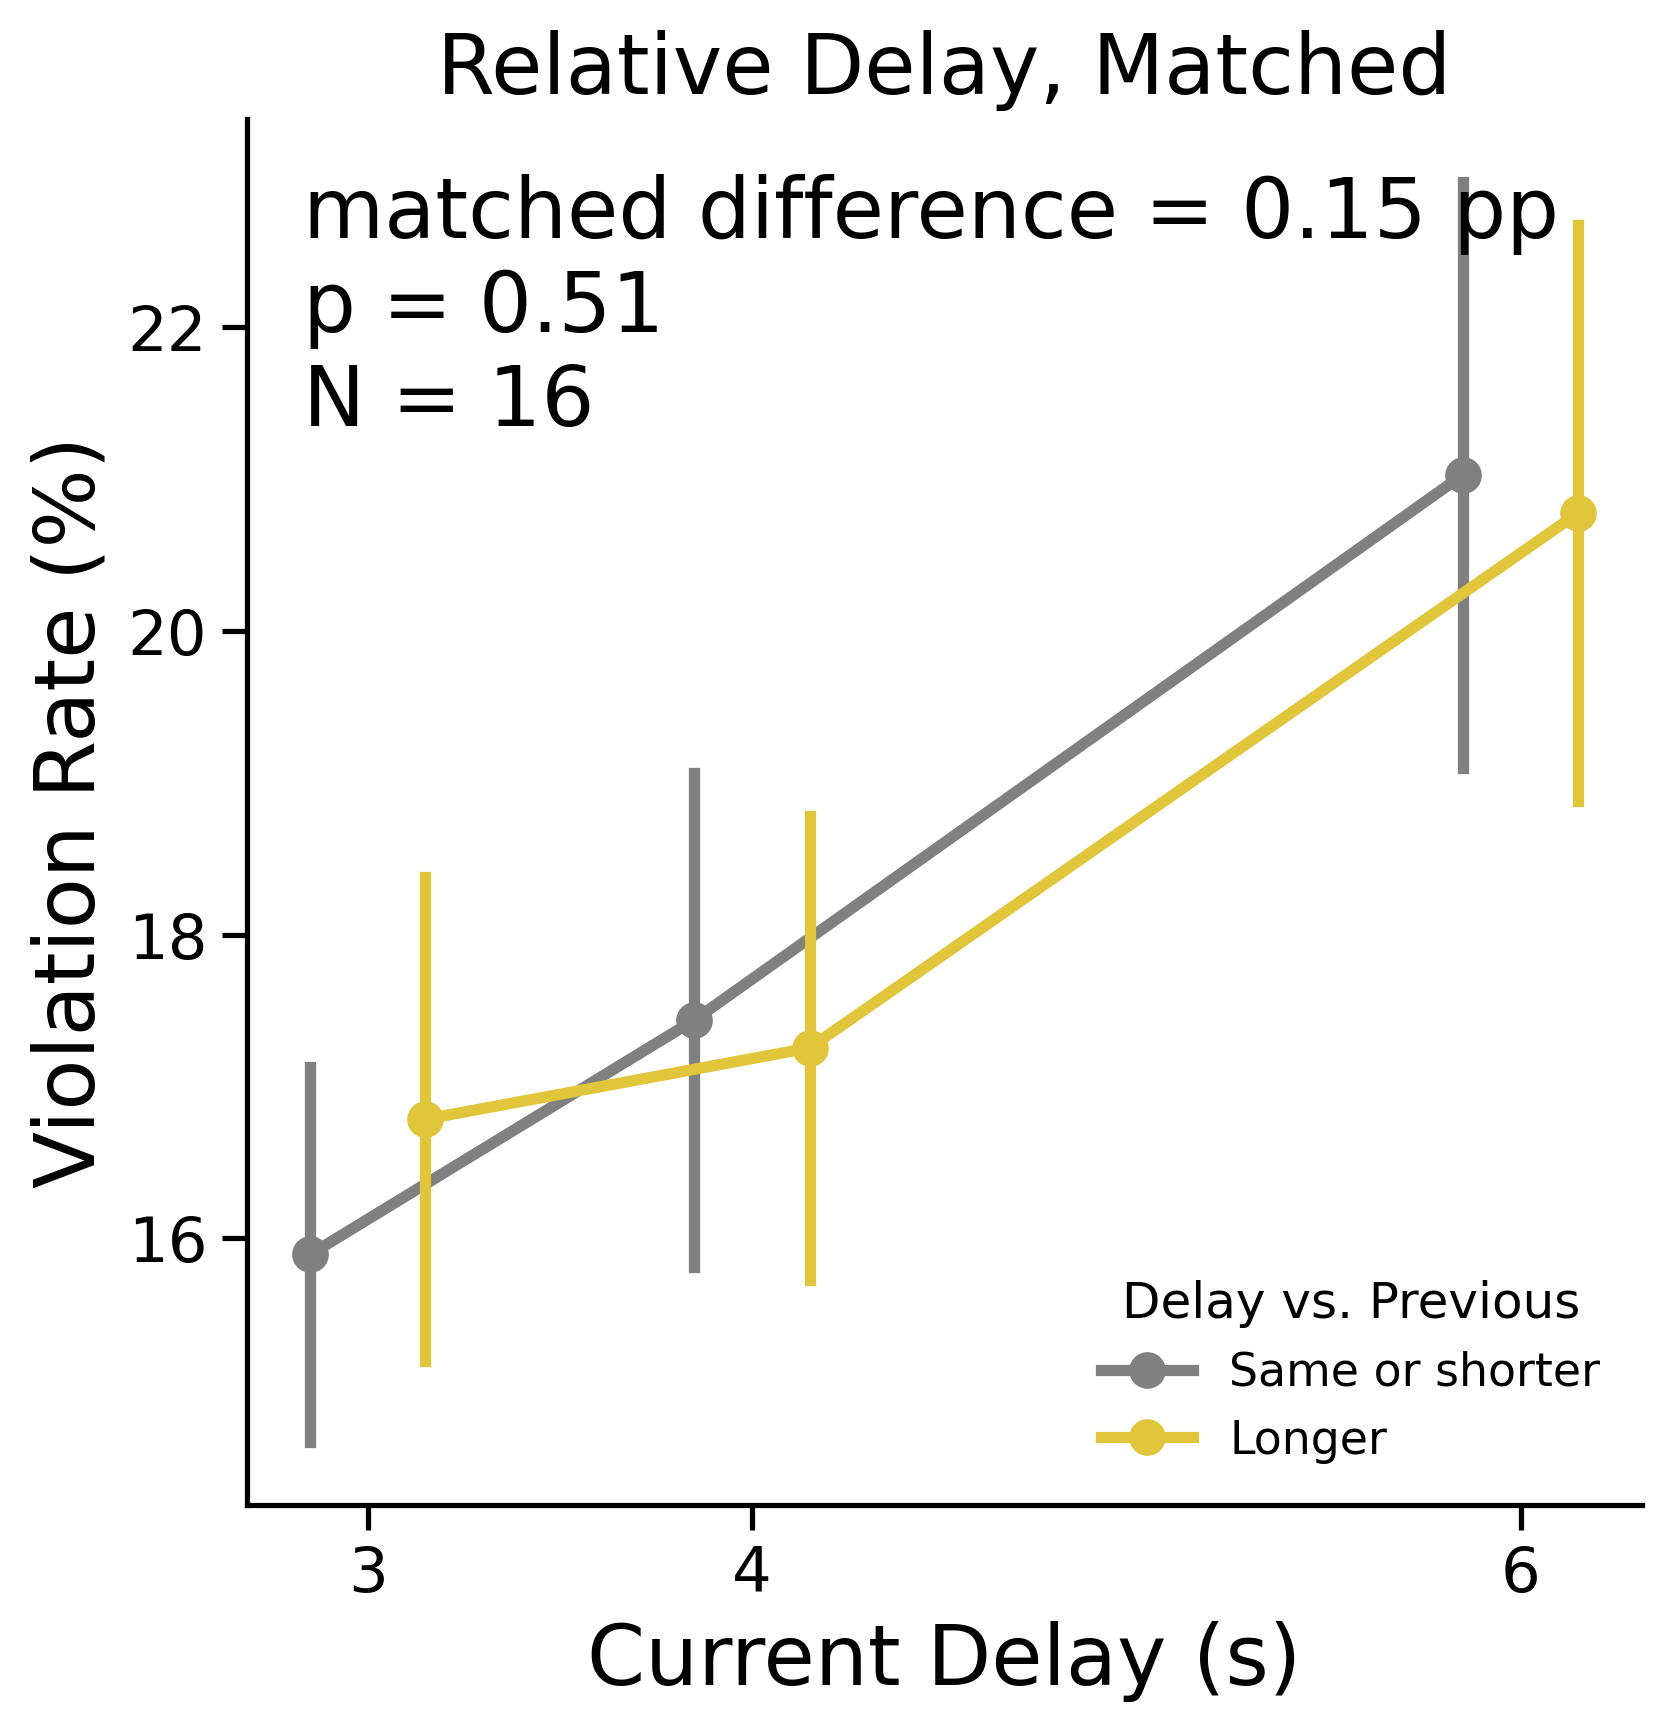

In [ ]:
matched_stats = delay_statistics["relative_delay"]["delay_matched"]
fig, ax = plt.subplots(figsize=(6, 6))
sns.pointplot(
    data=matched_rates.query("delay_time > 2"),
    x="delay_time",
    y="viol_rate",
    hue="relative_delay",
    hue_order=RELATIVE_DELAY_ORDER,
    palette=["gray", VIOLATION_COLOR],
    errorbar="se",
    dodge=0.3,
    native_scale=True,
    ax=ax,
)
ax.text(
    0.04,
    0.96,
    f"matched difference = {matched_stats['mean_difference']:.2f} pp\n"
    f"p = {matched_stats['p_value']:.2g}\n"
    f"N = {matched_stats['n_animals']}",
    transform=ax.transAxes,
    va="top",
)
ax.legend(title="Delay vs. Previous", frameon=False, loc="lower right")
ax.set(
    xticks=TRAINED_DELAYS[1:],
    xlabel="Current Delay (s)",
    ylabel="Violation Rate (%)",
    title="Relative Delay, Matched",
)
sns.despine(ax=ax)

## Violation rate across session progress

Sessions differ in length and trial timestamps are unavailable, so each session is split into 10 equal fractions of its trials. The **all-trials** curve includes every trial (edge spikes visible in the first and last bins). The **trimmed** curve excludes the first and last 10 trials of each session before binning. Gray lines are individual animals; colored lines are mean ± SEM.

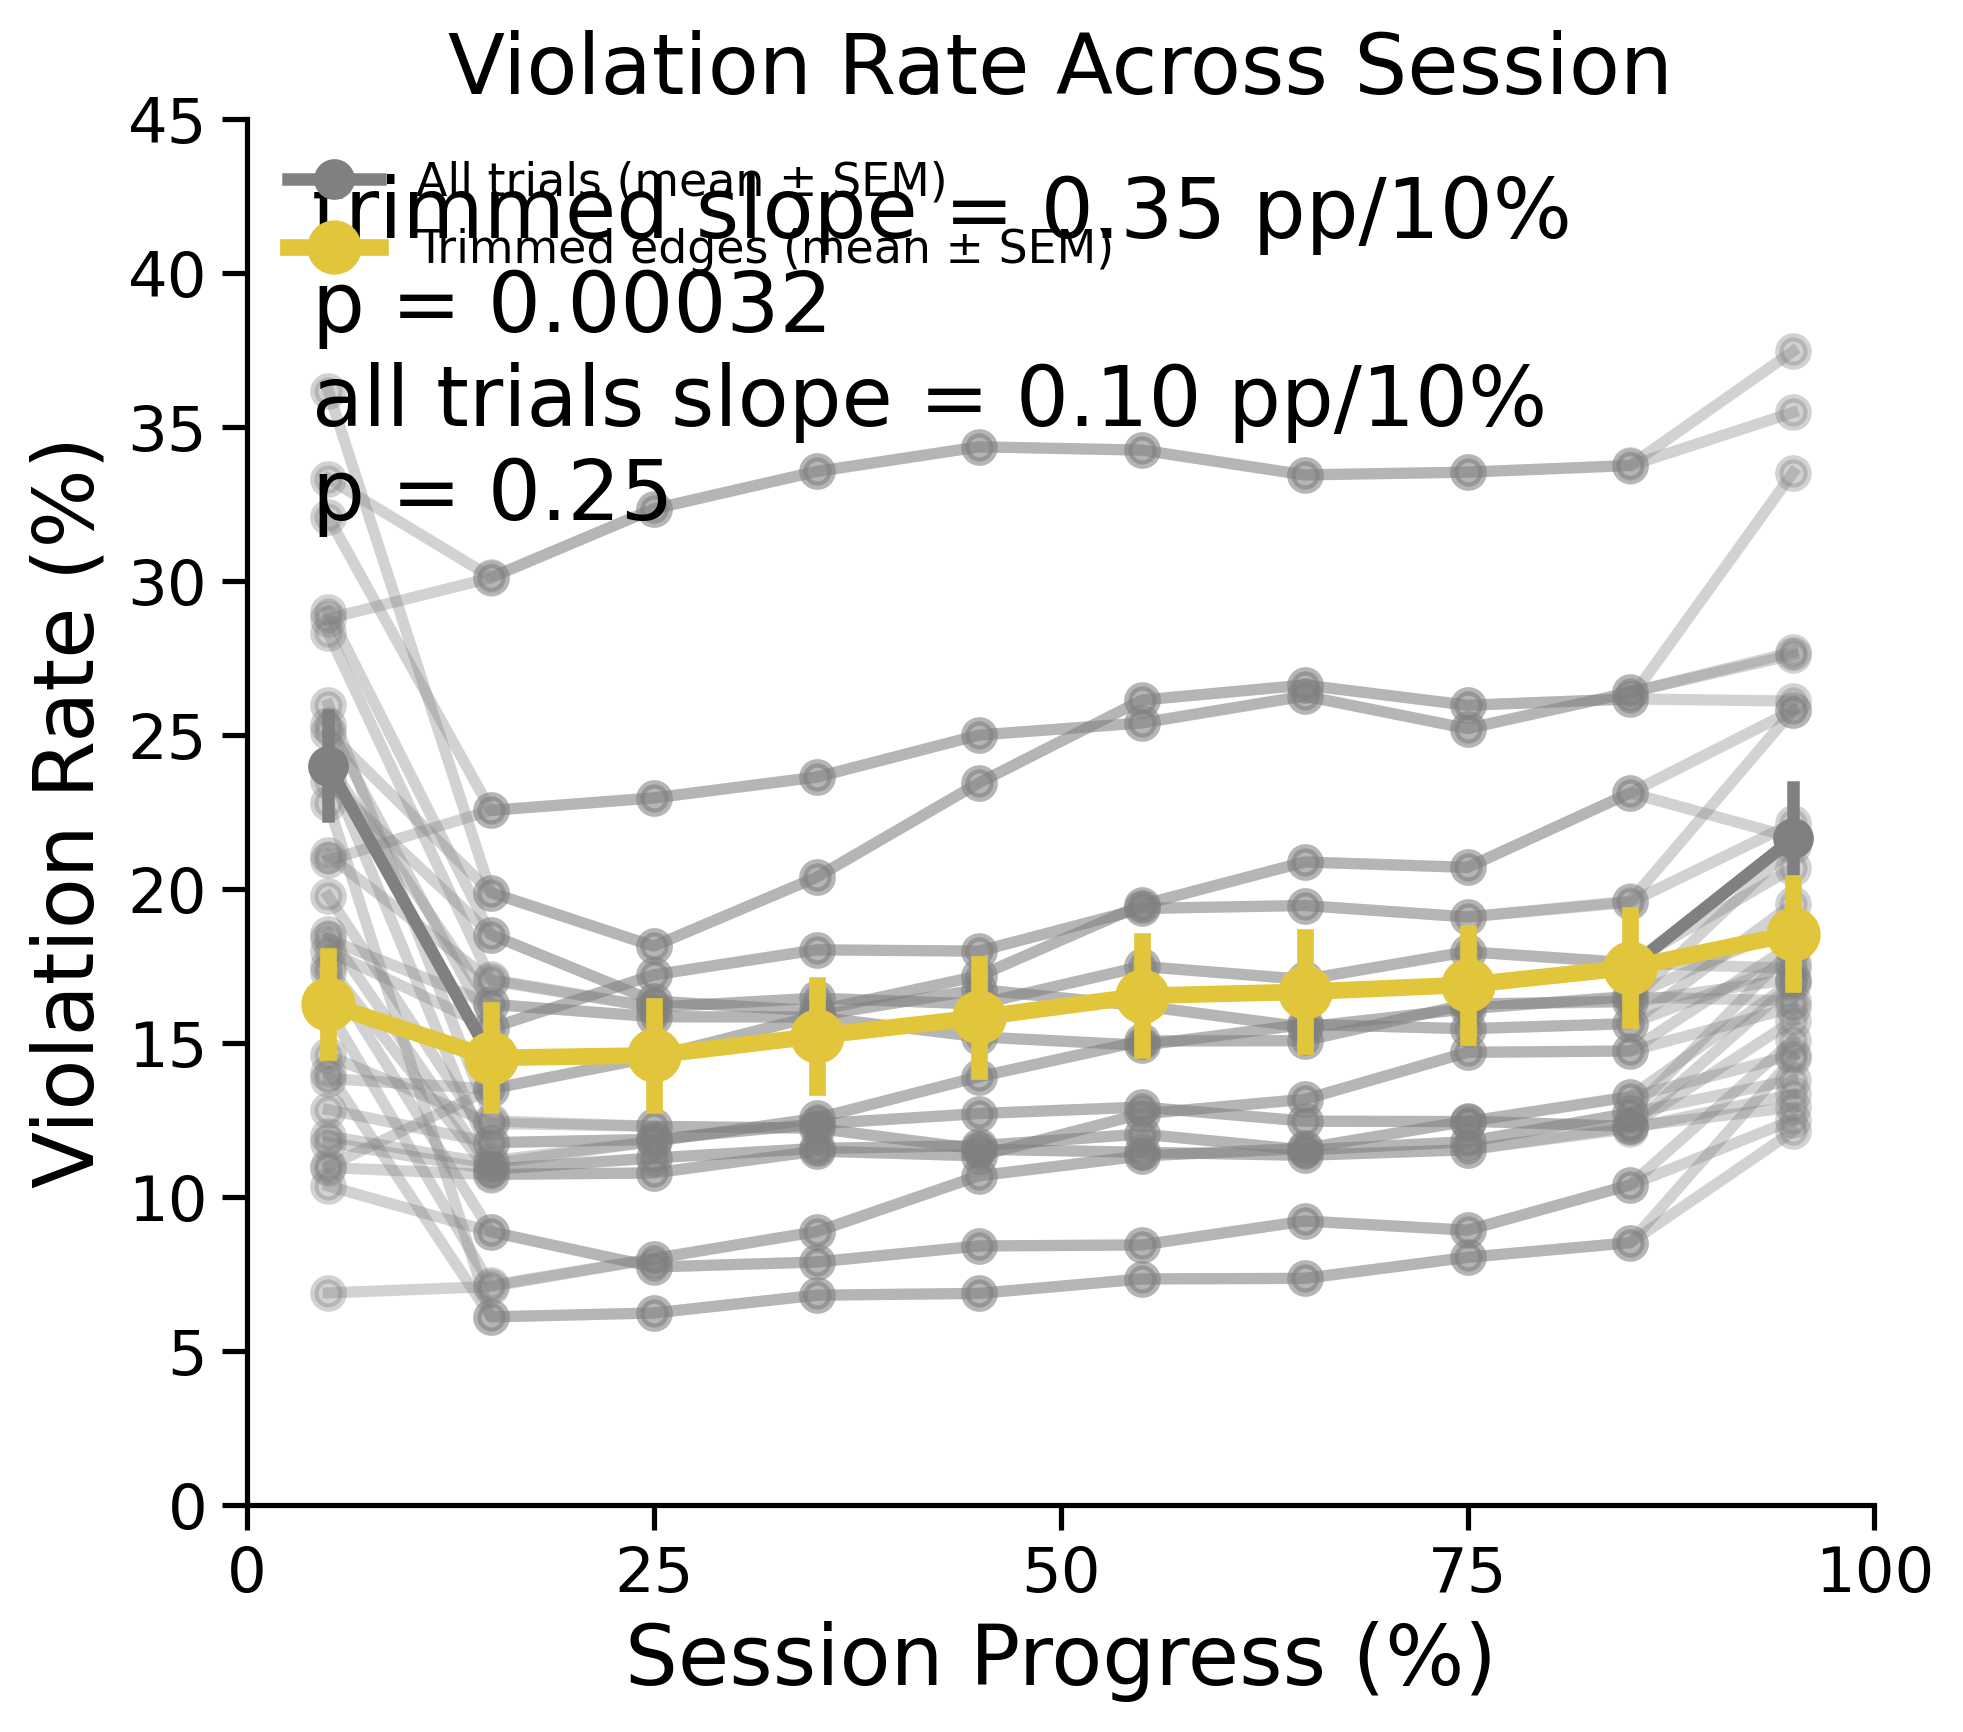

In [12]:
trim_stats = position_statistics["trimmed"]["slope_per_10_percent"]
all_stats = position_statistics["all_trials"]["slope_per_10_percent"]
fig, ax = plt.subplots(figsize=(7, 6))
for data, color, label in (
    (progress_rates_all, "0.5", "All trials (mean ± SEM)"),
    (progress_rates, VIOLATION_COLOR, "Trimmed edges (mean ± SEM)"),
):
    sns.pointplot(
        data=data,
        x="session_progress",
        y="viol_rate",
        hue="animal_id",
        palette=animal_grays,
        alpha=0.35,
        native_scale=True,
        legend=False,
        ax=ax,
    )
    sns.pointplot(
        data=data,
        x="session_progress",
        y="viol_rate",
        color=color,
        errorbar="se",
        linewidth=4 if color == VIOLATION_COLOR else 3,
        native_scale=True,
        label=label,
        ax=ax,
    )
ax.text(
    0.04,
    0.96,
    f"trimmed slope = {trim_stats['mean_slope']:.2f} pp/10%\n"
    f"p = {trim_stats['p_value']:.2g}\n"
    f"all trials slope = {all_stats['mean_slope']:.2f} pp/10%\n"
    f"p = {all_stats['p_value']:.2g}",
    transform=ax.transAxes,
    va="top",
)
ax.legend(frameon=False, loc="upper left")
ax.set(
    xticks=[0, 25, 50, 75, 100],
    xlabel="Session Progress (%)",
    ylabel="Violation Rate (%)",
    title="Violation Rate Across Session",
    ylim=(0, 45),
)
sns.despine(ax=ax)

## Violation rate at session start and end

Trials aligned to the start (1 = first trial) and end (−1 = final trial) of each session. Gray lines are individual animals; the colored line is the mean ± SEM. The start spike likely reflects water left in the ports from pre-session calibration; the end ramp likely reflects noise during the shared session changeover. Hit rate on non-violation trials also drops over the same trials (printed below), so the end ramp is not only a truncated final trial, although the final trial may be partly truncated by the session ending.

viol_rate  hit_rate
aligned_to trial_offset                     
End        -3                 32.5      75.5
           -2                 39.8      71.8
           -1                 53.6      56.2
Start       1                 95.4      58.2
            2                 74.2      58.4
            3                 57.5      62.6

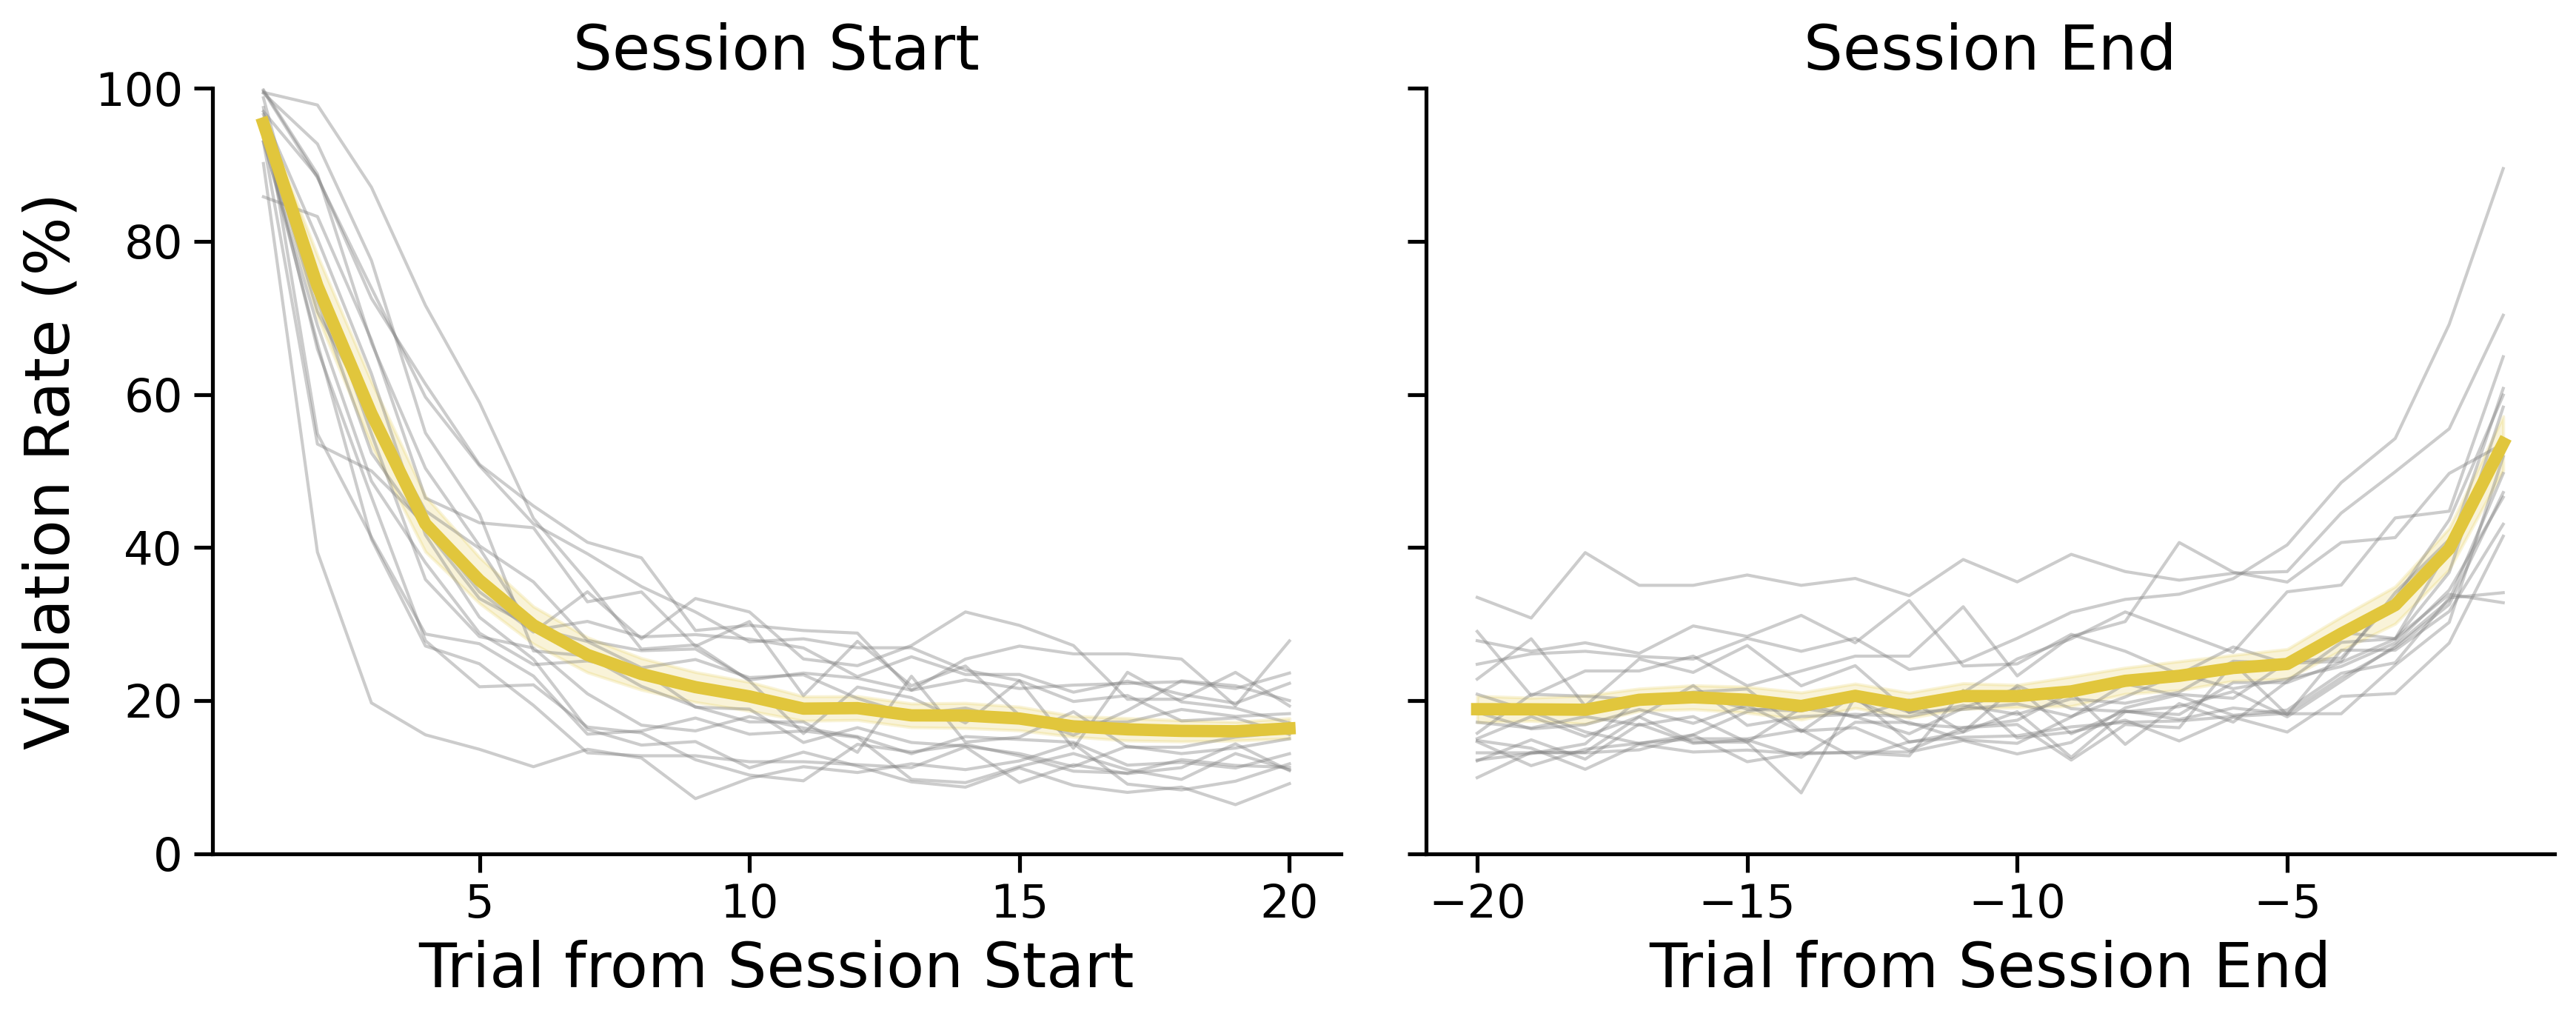

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, aligned_to in zip(axes, ("Start", "End"), strict=True):
    edge = edge_rates.query("aligned_to == @aligned_to")
    sns.lineplot(
        data=edge,
        x="trial_offset",
        y="viol_rate",
        units="animal_id",
        estimator=None,
        color="gray",
        alpha=0.4,
        linewidth=1,
        ax=ax,
    )
    sns.lineplot(
        data=edge,
        x="trial_offset",
        y="viol_rate",
        color=VIOLATION_COLOR,
        errorbar="se",
        linewidth=4,
        ax=ax,
    )
    ax.set(
        title=f"Session {aligned_to}",
        xlabel=f"Trial from Session {aligned_to}",
        ylabel="Violation Rate (%)",
        ylim=(0, 100),
    )
    sns.despine(ax=ax)
fig.tight_layout()

(
    edge_rates.query("trial_offset.abs() <= 3")
    .groupby(["aligned_to", "trial_offset"])[["viol_rate", "hit_rate"]]
    .mean()
    .round(1)
)

## Robustness — session edges (Figure 3 autocorrelation)

Recompute session-level violation autocorrelation after dropping the first and last 10 trials of each session (same 10,000 within-session permutations and seed 47 as Figure 3). Overlay observed curves and print Bonferroni-significant positive lags 1–5. The post-violation effect is P(violation | previous trial violated) − P(violation | previous trial valid), per animal.

Significant lags 1–5 (full): [1, 2, 3, 4, 5]
Significant lags 1–5 (trimmed): [1, 2, 3, 4, 5]
Lag-1 observed: 0.11708833019806736 -> 0.07810140710440845


/var/folders/g4/l0_yc2ss2nvdqk_13sp3z6fc0000gn/T/ipykernel_55686/629665804.py:32: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  mask = table["significant"].fillna(
/var/folders/g4/l0_yc2ss2nvdqk_13sp3z6fc0000gn/T/ipykernel_55686/629665804.py:32: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  mask = table["significant"].fillna(


,mean_difference_pp,n_animals,n_positive,p_value,t
edge_trials_excluded,10.000000,10.0,10.0,1.000000e+01,10.000000
full,12.139969,16.0,16.0,2.105418e-09,12.645551
trimmed,9.863265,16.0,16.0,1.281986e-08,11.075918


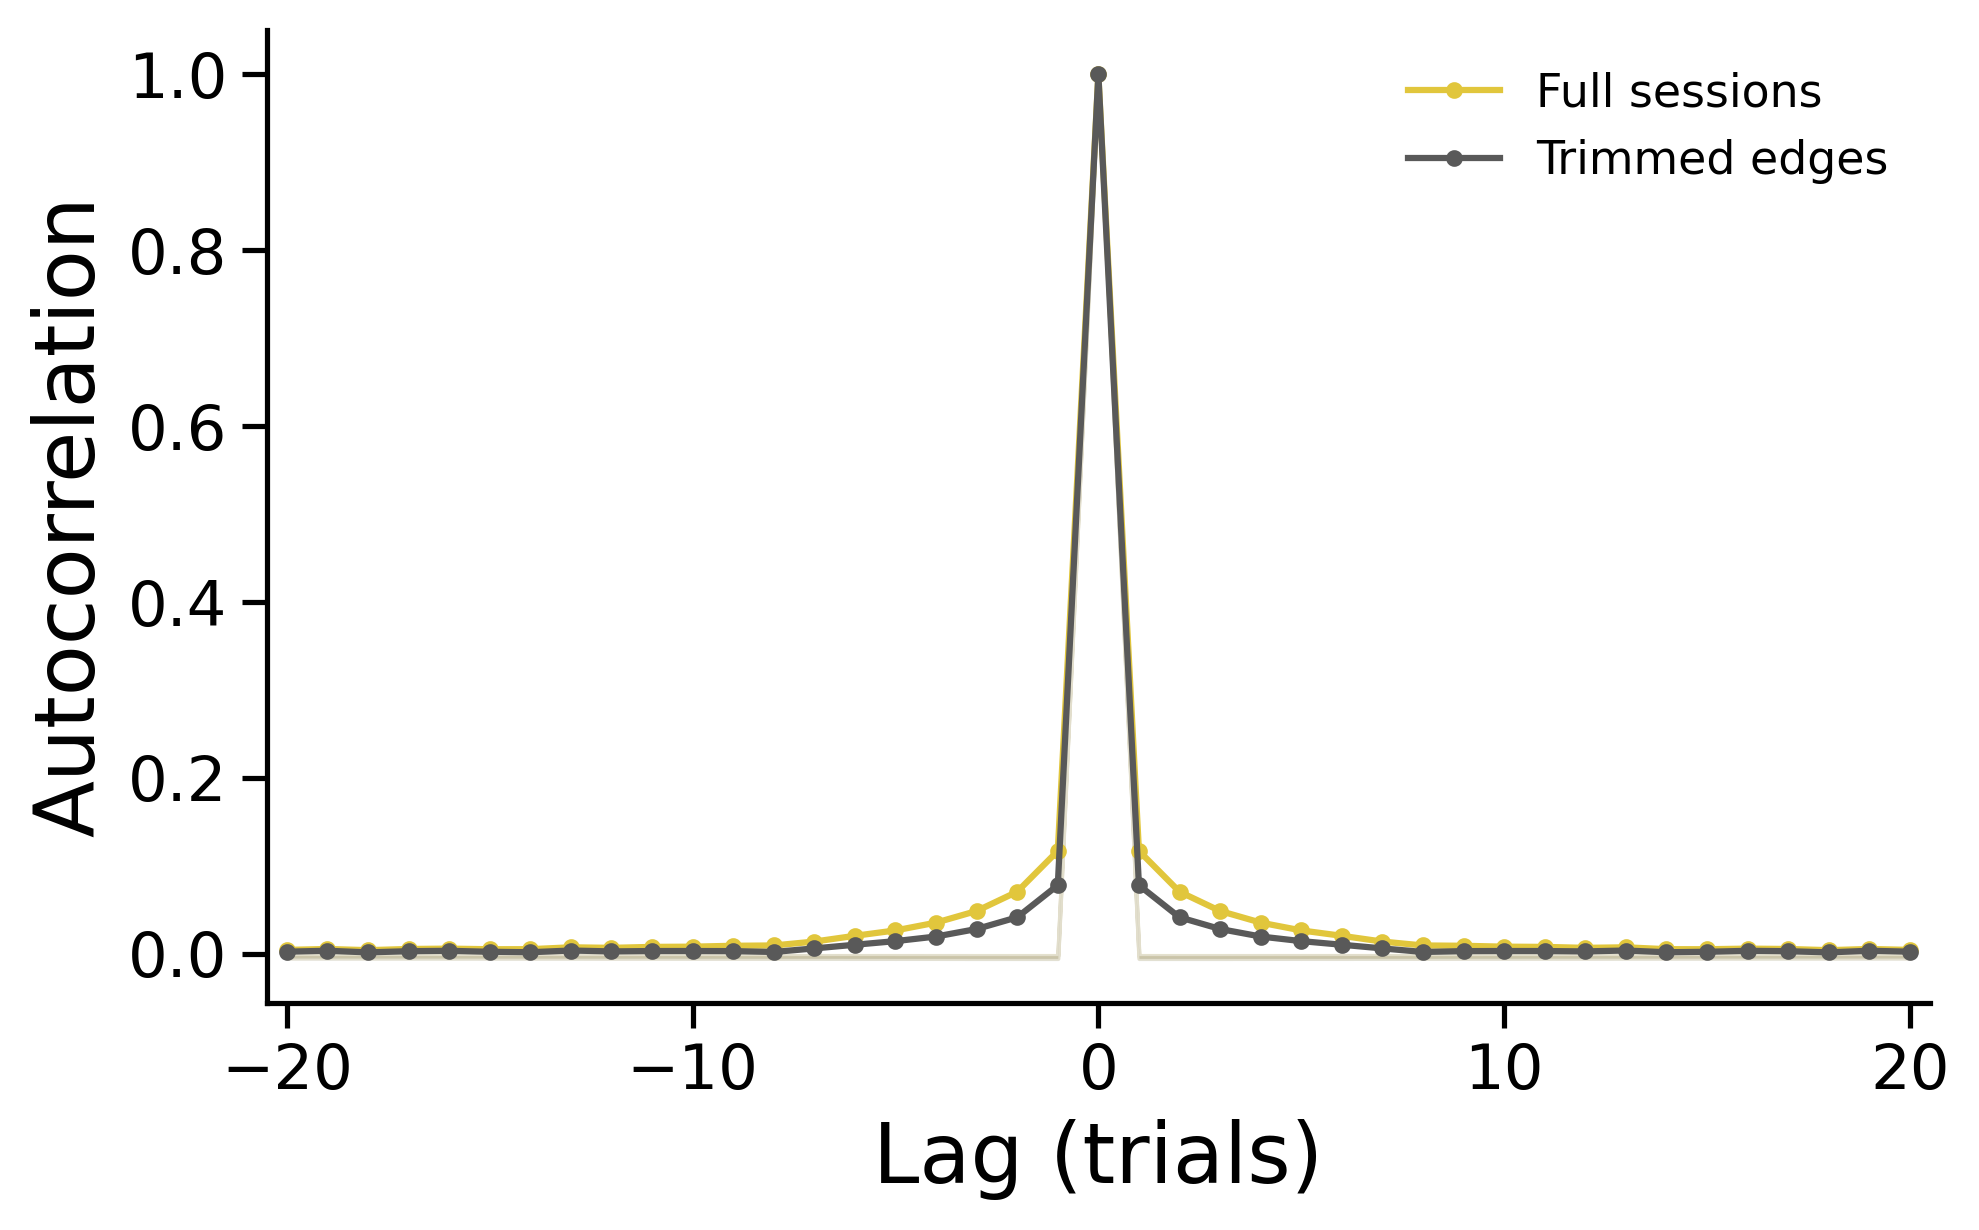

In [14]:
autocorr_full = load_autocorrelation_summary()
autocorr_trim = load_autocorrelation_summary(edges_trimmed=True)
history_robustness = load_history_robustness()

fig, ax = plt.subplots(figsize=(7, 4.5))
for table, color, label in (
    (autocorr_full, VIOLATION_COLOR, "Full sessions"),
    (autocorr_trim, "0.35", "Trimmed edges"),
):
    ax.plot(
        table["lag"],
        table["observed_mean"],
        color=color,
        marker="o",
        markersize=3,
        label=label,
    )
    ax.fill_between(
        table["lag"],
        table["null_ci_lower"],
        table["null_ci_upper"],
        color=color,
        alpha=0.15,
    )
ax.set(xlabel="Lag (trials)", ylabel="Autocorrelation", xlim=(-20.5, 20.5))
ax.legend(frameon=False)
sns.despine(ax=ax)
fig.tight_layout()


def sig_lags(table, max_lag=5):
    mask = table["significant"].fillna(
        False) & table["lag"].between(1, max_lag)
    return table.loc[mask, "lag"].astype(int).tolist()


print("Significant lags 1–5 (full):", sig_lags(autocorr_full))
print("Significant lags 1–5 (trimmed):", sig_lags(autocorr_trim))
print(
    "Lag-1 observed:",
    float(autocorr_full.loc[autocorr_full.lag == 1, "observed_mean"].iloc[0]),
    "->",
    float(autocorr_trim.loc[autocorr_trim.lag == 1, "observed_mean"].iloc[0]),
)
pd.DataFrame(history_robustness).T